# DialogXR Market Assessment: Greater Manchester Children's Social Care

**Bikal Technologies | Business Analytics Dissertation | Analysis Notebook**

## Business Problem

Bikal Technologies plans to take DialogXR into new markets. It needs evidence to judge whether Children's Social Care (CSC) is a credible market for DialogXR, and to identify the operational areas where its capabilities could create value. Greater Manchester (GM) is the case study: it has ten local authorities and an integrated children's safeguarding system. The approach is designed so that Bikal can reuse it for other regions.

## Research Objectives

| Objective | Question | Analysis in this notebook |
|---|---|---|
| **O1. Scale** | Is the market large enough? | Section 3: CSC expenditure and Children Looked After (CLA) share |
| **O2. Need** | Is there real operational pressure, compared with England? | Sections 4–5: GM vs England (2024 and 2017–2025 trend), variation within GM |
| **O3. Fit and targeting** | What drives workforce pressure, and which authorities are most affected? | Sections 6–10: pressure profiles, regression models, application to GM |
| **O4. Recommendation** | What should Bikal do, and how should value be measured? | Sections 11–12: market-entry implications and evaluation framework |

## Analytical Pipeline

1. **Descriptive analytics** (Sections 3–6): what does the GM market look like?
2. **Statistical modelling** (Sections 7–9): a national model of what is associated with, and what predicts, workforce pressure. The national dataset (about 150 authorities, 2017–2025) is used because ten authorities are too few for regression.
3. **Application** (Section 10): the national model is applied to the ten GM authorities.
4. **Prescriptive output** (Sections 11–12): implications and evaluation design for Bikal.

## Data

- **RO3 2023–24 outturn** (DLUHC/MHCLG): local-authority social care expenditure, £000.
- **Children's Social Work Workforce (CSWW) indicators 2017–2025** (DfE): workforce, vacancies, agency use, turnover, caseload and absence, by local authority and year (snapshot at 30 September).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    display
except NameError:
    display = print

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

RO3_FILE = "RO3_2023-2024_Outturn.csv"
CSWW_FILE = "csww_indicators_2017_to_2025.csv"

GM = ["Bolton", "Bury", "Manchester", "Oldham", "Rochdale",
      "Salford", "Stockport", "Tameside", "Trafford", "Wigan"]
EXCLUDE = ["City of London", "Isles of Scilly"]   # very small authorities with extreme ratios
PROFILE_YEAR = 2024                              # CSWW year used for the GM descriptive analysis

GM_COLOR, ENG_COLOR = "#c53030", "#718096"

## 2. Data Preparation

### 2.1 RO3 Expenditure

RO3 lists 528 bodies. Most are district councils (class SD) or other bodies (class O) without children's services responsibilities. Only **upper-tier authorities** are kept: unitary authorities (UA), metropolitan districts (MD), London boroughs (LB) and shire counties (SC). Aggregate rows (e.g. `E06`, `E08`) are removed. Values are converted to numbers after removing thousands separators.

CSWW reports two areas jointly (North and West Northamptonshire; Kingston upon Thames and Richmond upon Thames), so their RO3 values are summed to match.

In [2]:
def to_num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", "").str.strip(), errors="coerce")

raw = pd.read_csv(RO3_FILE)
raw.columns = [c.strip() for c in raw.columns]
print("RO3 raw shape:", raw.shape)
print("Classes:", raw["Class"].value_counts().to_dict())

ro3_vars = {
    "TOTAL CHILDREN SOCIAL CARE-Net Current Expenditure": "csc_net",
    "TOTAL CHILDREN SOCIAL CARE-Total Expenditure": "csc_gross",
    "CSC-Children_Looked_After-Net Current Expenditure": "cla_net",
}
cla_parts = [c for c in raw.columns if c.startswith("CSC-Children_Looked_After_of") and c.endswith("Net Current Expenditure")]

ro3 = raw[raw["Class"].isin(["UA", "MD", "LB", "SC"]) & (raw["ONS Code"].str.len() > 3)].copy()
for raw_col, new_col in ro3_vars.items():
    ro3[new_col] = to_num(ro3[raw_col])
ro3["cla_parts_sum"] = ro3[cla_parts].apply(to_num).sum(axis=1)
ro3 = ro3[["ONS Code", "Local authority", "Class"] + list(ro3_vars.values()) + ["cla_parts_sum"]]
print("Upper-tier authorities:", len(ro3))
print("CLA sub-categories used in the reconciliation check:")
for c in cla_parts:
    print("  -", c)

RO3 raw shape: (528, 525)
Classes: {'SD': 165, 'O': 100, 'UA': 64, 'MD': 37, 'LB': 34, 'SC': 22, 'Eng': 1, 'Class': 1}
Upper-tier authorities: 153
CLA sub-categories used in the reconciliation check:
  - CSC-Children_Looked_After_of _which_ residential_ care-Net Current Expenditure
  - CSC-Children_Looked_After_of _which_ fostering_ services-Net Current Expenditure
  - CSC-Children_Looked_After_of _which_ asylum_ looked_ after-Net Current Expenditure
  - CSC-Children_Looked_After_of _which_ other-Net Current Expenditure


### 2.2 CSWW Workforce Indicators

Only local-authority rows are kept. Indicators are converted to numbers. A **starter rate** (starters / in-post FTE) and a **London** indicator are added for the models.

In [3]:
csww = pd.read_csv(CSWW_FILE, low_memory=False)
print("CSWW raw shape:", csww.shape)
csww = csww[csww["geographic_level"] == "Local authority"].copy()

num_cols = ["inpost_fte", "agency_fte", "agency_rate_fte", "vacancy_fte", "vacancy_rate_fte",
            "turnover_rate_fte", "starters_fte", "leavers_fte", "cases", "case_holders_fte",
            "caseload_fte", "absence_rate_fte"]
for col in num_cols:
    csww[col] = pd.to_numeric(csww[col], errors="coerce")

combined = {
    "North Northamptonshire / West Northamptonshire": ["E06000061", "E06000062"],
    "Kingston upon Thames / Richmond upon Thames": ["E09000021", "E09000027"],
}
for name, codes in combined.items():
    joint_code = csww.loc[csww["la_name"] == name, "new_la_code"].iloc[0]
    part = ro3[ro3["ONS Code"].isin(codes)]
    row = {"ONS Code": joint_code, "Local authority": name, "Class": part["Class"].iloc[0]}
    for v in list(ro3_vars.values()) + ["cla_parts_sum"]:
        row[v] = part[v].sum()
    ro3 = pd.concat([ro3[~ro3["ONS Code"].isin(codes)], pd.DataFrame([row])], ignore_index=True)

csww = csww[~csww["la_name"].isin(EXCLUDE)].copy()
csww["is_gm"] = csww["la_name"].isin(GM)
csww["london"] = csww["region_name"].isin(["Inner London", "Outer London"]).astype(int)
csww["starter_rate"] = 100 * csww["starters_fte"] / csww["inpost_fte"]

print("CSWW local-authority rows, 2017–2025:", len(csww))
print("Authorities per year:", csww.groupby("time_period")["la_name"].nunique().to_dict())

CSWW raw shape: (1463, 32)
CSWW local-authority rows, 2017–2025: 1337
Authorities per year: {2017: 149, 2018: 149, 2019: 148, 2020: 148, 2021: 148, 2022: 148, 2023: 149, 2024: 149, 2025: 149}


### 2.3 Integration and Data Quality Audit

RO3 and CSWW are joined on the ONS authority code. The checks confirm that every authority matches once, that all ten GM authorities are present, and that the GM inputs have no missing values.

In [4]:
def integrate(year):
    d = ro3.merge(csww[csww.time_period == year], left_on="ONS Code", right_on="new_la_code",
                  how="inner", validate="one_to_one")
    d["spend_per_case"] = d["csc_net"] / d["cases"]
    return d

audit = ro3.merge(csww[csww.time_period == PROFILE_YEAR], left_on="ONS Code",
                  right_on="new_la_code", how="outer", indicator=True)
print("Merge audit:", audit["_merge"].value_counts().to_dict())
print("Unmatched RO3 rows (excluded by design):",
      audit.loc[audit["_merge"] == "left_only", "Local authority"].tolist())

nat = integrate(PROFILE_YEAR)
gm = nat[nat.is_gm].copy().set_index("la_name").sort_index()

gm_inputs = ["csc_net", "cla_net", "cases", "inpost_fte", "agency_rate_fte",
             "vacancy_rate_fte", "turnover_rate_fte", "caseload_fte"]
assert len(gm) == 10 and set(gm.index) == set(GM), "GM coverage problem"
assert gm[gm_inputs].notna().all().all(), "Missing GM input values"
print("National integrated authorities:", len(nat))
print("GM authorities:", len(gm), "| missing GM input values:", int(gm[gm_inputs].isna().sum().sum()))

Merge audit: {'both': 149, 'left_only': 2, 'right_only': 0}
Unmatched RO3 rows (excluded by design): ['Isles of Scilly', 'City of London']
National integrated authorities: 149
GM authorities: 10 | missing GM input values: 0


### 2.4 Data Audit Trail

**Why.** A reader must be able to trace every observation from the raw files to each analysis. The table below records how many rows remain after each step, and why rows were removed.

In [5]:
raw_ro3_rows = len(raw)
upper_tier_rows = raw["Class"].isin(["UA", "MD", "LB", "SC"]).sum()
upper_tier_valid = (raw["Class"].isin(["UA", "MD", "LB", "SC"]) & (raw["ONS Code"].str.len() > 3)).sum()
csww_raw_all = pd.read_csv(CSWW_FILE, low_memory=False)
csww_la_all = csww_raw_all[csww_raw_all.geographic_level == "Local authority"]

m1_2024 = nat.dropna(subset=["csc_net", "cases", "agency_rate_fte", "vacancy_rate_fte",
                             "turnover_rate_fte", "caseload_fte", "absence_rate_fte"])
panel_tmp = csww.sort_values(["new_la_code", "time_period"]).copy()
panel_tmp["y_next"] = panel_tmp.groupby("new_la_code")["agency_rate_fte"].shift(-1)
panel_tmp["year_next"] = panel_tmp.groupby("new_la_code")["time_period"].shift(-1)
m2_feats_tmp = ["agency_rate_fte", "vacancy_rate_fte", "turnover_rate_fte", "caseload_fte",
                "absence_rate_fte", "starter_rate", "london"]
panel_ok = panel_tmp.dropna(subset=m2_feats_tmp + ["y_next"])
panel_ok = panel_ok[panel_ok.year_next == panel_ok.time_period + 1]

audit_trail = pd.DataFrame([
    ["RO3 raw file", raw_ro3_rows, "All bodies reporting to MHCLG"],
    ["Keep upper-tier classes (UA, MD, LB, SC)", upper_tier_rows, "Remove districts (SD) and other bodies (O) with no children's services"],
    ["Remove aggregate rows (E06, E08, E09, E10)", upper_tier_valid, "Class totals are not authorities"],
    ["Combine jointly reported areas", len(ro3), "Northamptonshire (2 → 1) and Kingston/Richmond (2 → 1)"],
    ["CSWW raw file (all years, all levels)", len(csww_raw_all), "National, regional and local-authority rows, 2017–2025"],
    ["CSWW local-authority rows", len(csww_la_all), "Remove national and regional rows"],
    ["Exclude City of London and Isles of Scilly", len(csww), "Very small units with extreme ratios"],
    [f"RO3 × CSWW {PROFILE_YEAR} matched", len(nat), "One-to-one join on ONS code"],
    ["Model 1 complete cases (2024)", len(m1_2024), "Authorities missing any model variable dropped"],
    ["Model 2 panel pairs (agency outcome)", len(panel_ok), "Consecutive-year pairs with complete predictors and outcome"],
], columns=["Step", "Rows remaining", "Reason"])
display(audit_trail)

                                         Step  Rows remaining                                                                  Reason
0                                RO3 raw file             528                                           All bodies reporting to MHCLG
1    Keep upper-tier classes (UA, MD, LB, SC)             157  Remove districts (SD) and other bodies (O) with no children's services
2  Remove aggregate rows (E06, E08, E09, E10)             153                                        Class totals are not authorities
3              Combine jointly reported areas             151                  Northamptonshire (2 → 1) and Kingston/Richmond (2 → 1)
4       CSWW raw file (all years, all levels)            1463                  National, regional and local-authority rows, 2017–2025
5                   CSWW local-authority rows            1355                                       Remove national and regional rows
6  Exclude City of London and Isles of Scilly            1337 

### 2.5 Missing Values

**Why.** Missing values can bias results if they are not random, so they are counted and their handling is stated explicitly.

In [6]:
check_vars = ["csc_net", "cla_net", "cases", "case_holders_fte", "inpost_fte", "agency_fte", "agency_rate_fte",
              "vacancy_rate_fte", "turnover_rate_fte", "caseload_fte", "absence_rate_fte", "starters_fte", "leavers_fte"]
miss_cs = pd.DataFrame({
    f"Missing ({PROFILE_YEAR}, n={len(nat)})": nat[check_vars].isna().sum(),
    "% missing": (100 * nat[check_vars].isna().mean()).round(1),
    "Authorities affected": [", ".join(nat.loc[nat[v].isna(), "la_name"].tolist()) or "–" for v in check_vars],
})
display(miss_cs)

miss_panel = (100 * csww[check_vars[2:]].isna().mean()).round(1).rename("% missing, CSWW panel 2017–2025")
display(miss_panel.to_frame())
print("Missing values in the ten GM authorities (all years):", int(csww[csww.is_gm][check_vars[2:]].isna().sum().sum()))

                   Missing (2024, n=149)  % missing                                         Authorities affected
csc_net                                2        1.3                          Birmingham, Westmorland and Furness
cla_net                                2        1.3                          Birmingham, Westmorland and Furness
cases                                  1        0.7                                                   Birmingham
case_holders_fte                       1        0.7                                                   Birmingham
inpost_fte                             0        0.0                                                            –
agency_fte                             4        2.7  Birmingham, Kensington and Chelsea, Sunderland, Westminster
agency_rate_fte                        4        2.7  Birmingham, Kensington and Chelsea, Sunderland, Westminster
vacancy_rate_fte                       0        0.0                                             

**Handling.** Missingness is low (at most 2.7% for any variable in 2024, and at most 1.0% across the 2017–2025 panel) and affects a small number of non-GM authorities: agency figures for Birmingham, Kensington and Chelsea, Sunderland and Westminster; most Birmingham workforce figures; and RO3 expenditure for Birmingham and Westmorland and Furness. No GM value is missing. **Complete-case analysis** is used: each analysis drops only the authorities missing a variable it needs. Imputation was rejected because it would invent workforce figures for named authorities, which Bikal could then mistake for real data; with so few missing values, the loss of precision is small. Missing values are never set to zero.

### 2.6 Feature Engineering

| Feature | Formula | Why it was created |
|---|---|---|
| `spend_per_case` | CSC net expenditure (£000) / cases | Financial intensity on a comparable scale across authorities of different size |
| `log_spend`, `log_cases` | natural log | Reduce right skew; coefficients read as % differences; log(cases) controls for scale (Model 1) |
| `starter_rate` | 100 × starters FTE / in-post FTE | Captures recruitment inflow, which may offset future agency use (Model 2) |
| `london`, `inner_london`, `outer_london` | 1 if the authority is in London, else 0 | Controls for higher London labour and accommodation costs |
| `y_next` | outcome value for the same authority in year t + 1 | Turns the panel into a forecasting problem (Model 2) |
| Year dummies | 1 for each reporting year except the first | Year fixed effects absorb national shocks (inference model) |
| Pooled rates | sum of numerators / sum of denominators | Workforce-weighted regional rates for benchmarking |
| z-scores, median/IQR scores | (x − mean) / sd; (x − median) / IQR | Put indicators on a common scale for pressure profiles |
| `spend_per_total_workforce` | CSC net expenditure / (in-post + agency FTE) | Tests whether an earlier ratio was a denominator artefact |

Official DfE rates (agency, vacancy, turnover, caseload) are used as published rather than recalculated, so the analysis matches the government's definitions.

### 2.7 Exploratory Data Analysis: National Data Summary

**Why.** Before modelling, the distributions, relationships and unusual values in the national data must be understood. They determine which transformations are needed (for example, logs), which predictors overlap, and which observations could distort the models.

In [7]:
eda_vars = {"csc_net": "CSC net spend (£000)", "cases": "Cases", "spend_per_case": "Spend per case (£000)",
            "agency_rate_fte": "Agency rate (%)", "vacancy_rate_fte": "Vacancy rate (%)",
            "turnover_rate_fte": "Turnover rate (%)", "caseload_fte": "Caseload per FTE",
            "absence_rate_fte": "Absence rate (%)"}
eda = nat[list(eda_vars)].rename(columns=eda_vars)
summary_nat = eda.describe().T
summary_nat["skewness"] = eda.skew()
summary_nat["GM median"] = nat[nat.is_gm][list(eda_vars)].median().values
display(summary_nat.round(2))
print("Skewness of log(CSC net spend):", round(np.log(nat.csc_net).skew(), 2))

                       count      mean       std      min       25%       50%        75%        max  skewness  GM median
CSC net spend (£000)   147.0  96335.46  57387.61  8291.00  60742.00  79589.00  107665.50  322301.00      1.70   76039.50
Cases                  148.0   2125.58   1192.09   115.00   1316.25   1795.50    2586.75    6813.00      1.65    2076.00
Spend per case (£000)  147.0     46.40     12.20    23.11     38.98     44.97      51.33      92.49      1.10      39.11
Agency rate (%)        145.0     17.39     10.36     0.00      9.60     16.20      24.50      44.30      0.41      22.15
Vacancy rate (%)       149.0     17.82     10.63     0.00      9.70     17.20      24.10      50.90      0.58      17.05
Turnover rate (%)      148.0     15.09      5.81     4.60     11.20     13.85      17.70      41.20      1.51      16.00
Caseload per FTE       148.0     15.43      2.16    10.20     13.80     15.30      16.90      20.30      0.09      16.25
Absence rate (%)       147.0    

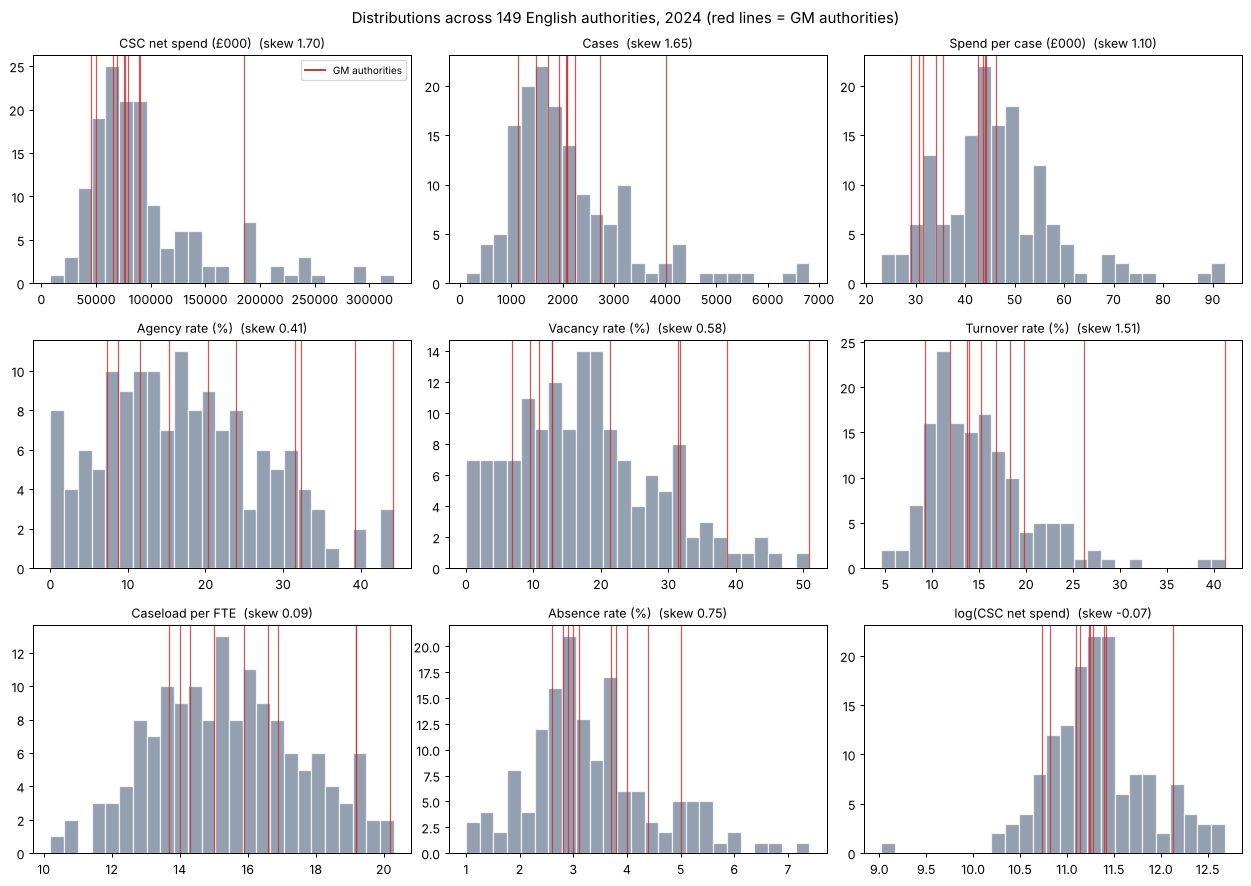

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
plot_vars = list(eda_vars.items()) + [("log_csc", "log(CSC net spend)")]
nat_plot = nat.assign(log_csc=np.log(nat.csc_net))
for ax, (col, label) in zip(axes.flat, plot_vars):
    vals = nat_plot[col].dropna()
    ax.hist(vals, bins=25, color=ENG_COLOR, alpha=0.75, edgecolor="white")
    for v in nat_plot.loc[nat_plot.is_gm, col].dropna():
        ax.axvline(v, color=GM_COLOR, lw=1, alpha=0.8)
    ax.set_title(f"{label}  (skew {vals.skew():.2f})", fontsize=10)
axes.flat[0].plot([], [], color=GM_COLOR, label="GM authorities"); axes.flat[0].legend(fontsize=8)
plt.suptitle(f"Distributions across {len(nat)} English authorities, {PROFILE_YEAR} (red lines = GM authorities)")
plt.tight_layout(); plt.show()

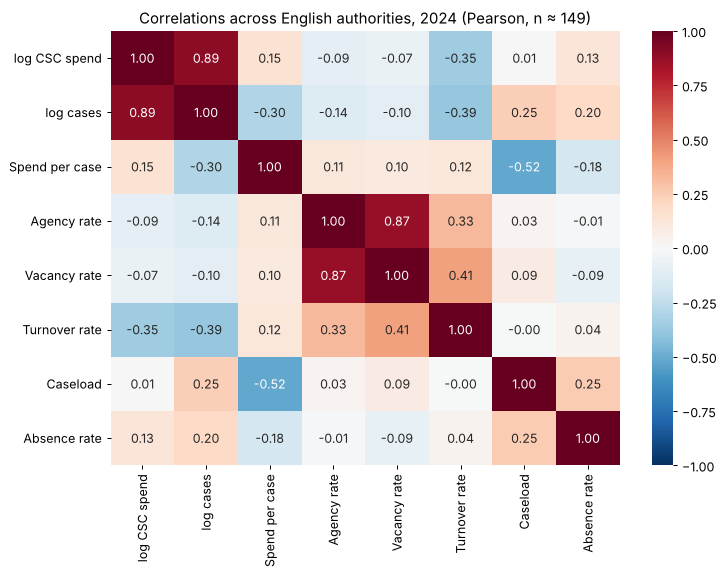

In [9]:
corr_vars = {"log_csc": "log CSC spend", "log_cases": "log cases", "spend_per_case": "Spend per case",
             "agency_rate_fte": "Agency rate", "vacancy_rate_fte": "Vacancy rate",
             "turnover_rate_fte": "Turnover rate", "caseload_fte": "Caseload", "absence_rate_fte": "Absence rate"}
corr_nat = nat.assign(log_csc=np.log(nat.csc_net), log_cases=np.log(nat.cases))[list(corr_vars)].corr()
corr_nat = corr_nat.rename(index=corr_vars, columns=corr_vars)
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr_nat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title(f"Correlations across English authorities, {PROFILE_YEAR} (Pearson, n ≈ {len(nat)})")
plt.tight_layout(); plt.show()

In [10]:
anomalies = []
for col, label in eda_vars.items():
    s = nat.set_index("la_name")[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    high = s[s > q3 + 1.5 * iqr].sort_values(ascending=False)
    low = s[s < q1 - 1.5 * iqr].sort_values()
    anomalies.append({"Variable": label, "High outliers (n)": len(high),
                      "Highest": ", ".join(f"{k} ({v:,.1f})" for k, v in high.head(3).items()) or "–",
                      "Low outliers (n)": len(low),
                      "Lowest": ", ".join(f"{k} ({v:,.1f})" for k, v in low.head(3).items()) or "–"})
display(pd.DataFrame(anomalies))

                Variable  High outliers (n)                                                           Highest  Low outliers (n) Lowest
0   CSC net spend (£000)                 17   Kent (322,301.0), Hampshire (290,644.0), Lancashire (284,968.0)                 0      –
1                  Cases                  7         Kent (6,813.0), Hampshire (6,729.0), Lancashire (6,333.0)                 0      –
2  Spend per case (£000)                  7  Hillingdon (92.5), Lambeth (91.5), Kensington and Chelsea (87.8)                 0      –
3        Agency rate (%)                  0                                                                 –                 0      –
4       Vacancy rate (%)                  2                  Tameside (50.9), Herefordshire, County of (46.2)                 0      –
5      Turnover rate (%)                  4                   Tameside (41.2), Rutland (39.6), Swindon (31.6)                 0      –
6       Caseload per FTE                  0            

### Findings: National Data Summary

- **Expenditure and cases are right-skewed** (skewness about 1.7), driven by large county councils such as Kent, Hampshire and Lancashire, which are flagged as high outliers. After a log transformation the skew of spending falls to −0.07, which supports modelling log(spend) rather than raw spend (Model 1).
- **Workforce indicators are only mildly skewed** (agency 0.41, vacancy 0.58, caseload 0.09), so they are used untransformed; turnover (1.51) is more skewed because of a few very high values.
- **Where GM sits.** GM's median agency rate (22.2%) is well above the national median (16.2%), its median caseload is higher (16.3 vs 15.3) and its median spend per case is lower (£39,100 vs £45,000). Its median vacancy rate is close to the national median (17.1% vs 17.2%): GM's higher pooled vacancy rate comes from a few authorities with very high vacancies (Tameside, Oldham, Trafford, Bury).
- **Agency and vacancy rates are strongly correlated nationally** (r = 0.87), confirming the multicollinearity seen in GM and justifying regularisation. Turnover is only moderately correlated with them nationally (r = 0.33 and 0.41), unlike in GM (0.82 and 0.87), which shows why ten authorities alone are not a reliable basis for generalisation.
- **log CSC spend and log cases are very strongly correlated** (r = 0.89), so case volume must be controlled for in any financial comparison.
- **Spend per case and caseload are negatively correlated** (r = −0.52) partly by construction, because both are divided by cases; this is why spend per case is not used as the outcome in Model 1.
- **Smaller authorities have higher turnover** (r = −0.39 between turnover and log cases): a few leavers produce a large rate in a small workforce. This matters for fair use of any ranking produced from these data (see the ethics and governance discussion in Chapter 3).
- **Anomalies.** Seven authorities have unusually high spend per case, led by London boroughs (Hillingdon £92,500, Lambeth £91,500, Kensington and Chelsea £87,800). Tameside is a high outlier nationally for both vacancy (50.9%) and turnover (41.2%). These are genuine values and are retained; robust (HC3) standard errors limit their influence, and the City of London and Isles of Scilly were excluded at the preparation stage.

## 3. Market Scale (O1)

**Why.** A market is only worth entering if it is large enough. Net current expenditure on CSC shows the size of the budget that DialogXR would support. The share spent on Children Looked After (CLA) shows how much of that budget goes on placements.

**Method.** Net current expenditure, RO3 2023–24 (£000). CLA share = CLA net expenditure / total CSC net expenditure. The regional share is pooled (sum of CLA / sum of CSC), so larger authorities carry more weight. A reconciliation check confirms that the CLA sub-categories add up to the CLA total, so nothing is double-counted.

            csc_gross   csc_net   cla_net  share_of_gm_csc_%  cla_share_%  cla_reconciliation_diff
la_name                                                                                           
Manchester   199745.0  185454.0  104824.0               22.4         56.5                      0.0
Tameside      92917.0   90425.0   58536.0               10.9         64.7                      0.0
Wigan         98190.0   88953.0   56604.0               10.8         63.6                      1.0
Oldham        87072.0   79140.0   42181.0                9.6         53.3                      0.0
Salford       91997.0   76539.0   23582.0                9.3         30.8                      0.0
Bolton        83251.0   75540.0   46620.0                9.1         61.7                      0.0
Rochdale      73750.0   68767.0   35679.0                8.3         51.9                      0.0
Stockport     72069.0   65868.0   35779.0                8.0         54.3                      0.0
Trafford  

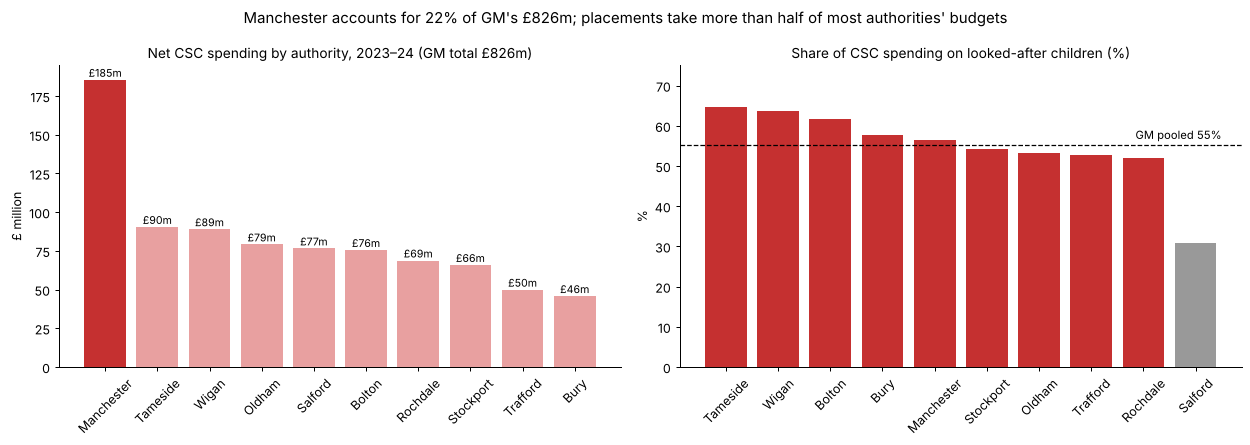

In [11]:
scale = gm[["csc_gross", "csc_net", "cla_net", "cla_parts_sum"]].copy()
scale["share_of_gm_csc_%"] = 100 * scale["csc_net"] / scale["csc_net"].sum()
scale["cla_share_%"] = 100 * scale["cla_net"] / scale["csc_net"]
scale["cla_reconciliation_diff"] = scale["cla_net"] - scale["cla_parts_sum"]
scale = scale.sort_values("csc_net", ascending=False)
display(scale.drop(columns="cla_parts_sum").round(1))

gm_total, gm_cla = scale.csc_net.sum(), scale.cla_net.sum()
eng_total = nat.csc_net.sum()
print(f"\nGM total CSC net expenditure: £{gm_total/1000:,.1f}m")
print(f"GM total CLA net expenditure: £{gm_cla/1000:,.1f}m  (pooled CLA share {100*gm_cla/gm_total:.1f}%)")
print(f"GM share of England CSC net expenditure: {100*gm_total/eng_total:.1f}%")
print("Max absolute CLA reconciliation difference (£000):", scale.cla_reconciliation_diff.abs().max())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
spend_m = scale.csc_net / 1000
bars = axes[0].bar(spend_m.index, spend_m.values, color=[GM_COLOR if a == "Manchester" else "#e8a0a0" for a in spend_m.index])
for b, v in zip(bars, spend_m.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 2, f"£{v:.0f}m", ha="center", fontsize=8.5)
axes[0].set_title("Net CSC spending by authority, 2023–24 (GM total £826m)", fontsize=11)
axes[0].set_ylabel("£ million"); axes[0].spines[["top", "right"]].set_visible(False)
cla = scale["cla_share_%"].sort_values(ascending=False)
axes[1].bar(cla.index, cla.values, color=["#999999" if a == "Salford" else GM_COLOR for a in cla.index])
axes[1].axhline(100 * gm_cla / gm_total, ls="--", color="black", lw=1)
axes[1].text(len(cla) - 0.5, 100 * gm_cla / gm_total + 1.5, f"GM pooled {100 * gm_cla / gm_total:.0f}%", ha="right", fontsize=9)
axes[1].set_title("Share of CSC spending on looked-after children (%)", fontsize=11)
axes[1].set_ylabel("%"); axes[1].set_ylim(0, 75); axes[1].spines[["top", "right"]].set_visible(False)
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.suptitle("Manchester accounts for 22% of GM's £826m; placements take more than half of most authorities' budgets", fontsize=12)
plt.tight_layout(); plt.show()

### Findings: Market Scale

- GM authorities spent about **£826m** net on children's social care in 2023–24, about **6%** of the England total (5.8%).
- **Manchester** alone accounts for about 22% of GM spending (£185m). The other nine authorities each spend between £46m and £90m.
- **CLA placements** take about **55%** of GM CSC spending (about £456m). The share ranges from 31% (Salford) to 65% (Tameside).
- The CLA sub-categories reconcile to the CLA total (maximum difference £1k), so the figures are not double-counted.

**Business implication (O1).** GM is a substantial market: ten authorities with a combined budget of more than £800m, organised in one region. More than half of the budget goes on placements, so the remainder (social work teams, safeguarding, family support) is where an information and decision-support tool like DialogXR would sit.

## 4. Operational Need: GM Compared with England (O2)

### 4.1 Pooled Comparison, 2024

**Why.** To show that GM's pressure is real, it must be compared with a benchmark. A pooled rate (sum of numerators / sum of denominators) weights each authority by its workforce, so it describes the whole region rather than an average of ten very different authorities.

**Method.** Same definitions as the DfE indicators. Each indicator uses only authorities with both numerator and denominator available (complete cases).

In [12]:
POOLED = {
    "Agency rate (%)":   (["agency_fte", "inpost_fte"],    lambda d: 100 * d.agency_fte.sum() / (d.agency_fte.sum() + d.inpost_fte.sum())),
    "Vacancy rate (%)":  (["vacancy_fte", "inpost_fte"],   lambda d: 100 * d.vacancy_fte.sum() / (d.vacancy_fte.sum() + d.inpost_fte.sum())),
    "Turnover rate (%)": (["leavers_fte", "inpost_fte"],   lambda d: 100 * d.leavers_fte.sum() / d.inpost_fte.sum()),
    "Caseload per FTE":  (["cases", "case_holders_fte"],   lambda d: d.cases.sum() / d.case_holders_fte.sum()),
}
def pooled(df):
    return pd.Series({k: f(df.dropna(subset=cols)) for k, (cols, f) in POOLED.items()})

y24 = csww[csww.time_period == PROFILE_YEAR]
comparison = pd.DataFrame({"Greater Manchester": pooled(y24[y24.is_gm]),
                           "Rest of England": pooled(y24[~y24.is_gm])})
comparison["Difference"] = comparison["Greater Manchester"] - comparison["Rest of England"]
display(comparison.round(2))

                   Greater Manchester  Rest of England  Difference
Agency rate (%)                 20.89            16.05        4.84
Vacancy rate (%)                21.20            17.04        4.16
Turnover rate (%)               16.51            13.68        2.82
Caseload per FTE                16.38            15.30        1.08


### 4.2 Trend, 2017–2025

**Why.** A single year cannot show whether GM's pressure is long-standing or recent. A long-standing problem means more stable demand for a solution.

               Agency rate (%)                   Vacancy rate (%)                  Turnover rate (%)                   Caseload per FTE                
area        Greater Manchester Rest of England Greater Manchester Rest of England Greater Manchester Rest of England Greater Manchester Rest of England
time_period                                                                                                                                            
2017                      12.7            16.0               13.2            17.2               12.2            13.5               19.6            17.6
2018                      13.7            15.5               12.8            16.7               15.6            15.1               19.0            17.3
2019                      11.3            16.1               12.0            16.7               13.5            15.1               18.4            16.8
2020                      15.2            15.4               15.1            16.2       

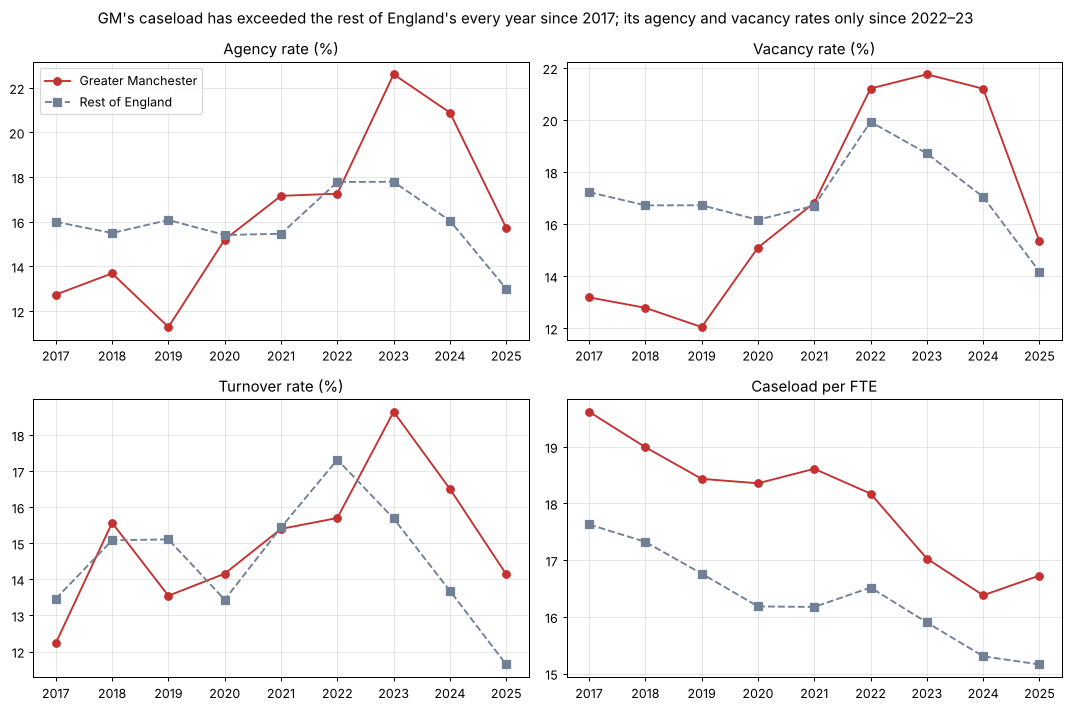

In [13]:
trend = (csww.groupby(["time_period", "is_gm"]).apply(pooled).reset_index()
         .assign(area=lambda d: np.where(d.is_gm, "Greater Manchester", "Rest of England")))
display(trend.pivot(index="time_period", columns="area",
                    values=["Agency rate (%)", "Vacancy rate (%)", "Turnover rate (%)", "Caseload per FTE"]).round(1))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, ind in zip(axes.flat, list(POOLED)):
    for area, style, col in [("Greater Manchester", "-o", GM_COLOR), ("Rest of England", "--s", ENG_COLOR)]:
        sub = trend[trend.area == area]
        ax.plot(sub.time_period, sub[ind], style, color=col, label=area)
    ax.set_title(ind); ax.grid(alpha=0.3)
axes[0, 0].legend()
plt.suptitle("GM's caseload has exceeded the rest of England's every year since 2017; its agency and vacancy rates only since 2022–23", fontsize=12)
plt.tight_layout(); plt.show()

### Findings: Operational Need

- **In 2024, GM was above the rest of England on all four indicators:** agency rate (20.9% vs 16.0%), vacancy rate (21.2% vs 17.0%), turnover (16.5% vs 13.7%) and caseload (16.4 vs 15.3 cases per FTE).
- **Caseload pressure is long-standing.** GM's caseload was higher than the rest of England in every year from 2017 to 2025.
- **Agency and vacancy pressure is recent.** In 2017–2019, GM had *lower* agency and vacancy rates than the rest of England. The lines crossed around 2021–2022. By 2023–2024 GM was clearly above. In 2025 both areas improved and the gap narrowed, but GM remained above.
- **Turnover** fluctuates in both areas; GM has been above England since 2023.

**Business implication (O2).** The need is real and measurable. GM shows two kinds of pressure: long-standing **workload** pressure and more recent **workforce instability**. The data describe these pressures; they do not identify their causes (for example demand, deprivation, placement shortages or labour-market competition). The models in Sections 7–9 examine which indicators are associated with workforce pressure.

## 5. Variation within Greater Manchester (O2)

**Why.** A regional average can hide very different situations. Bikal needs to know whether the ten authorities face the same problems or different ones, because that decides whether one message fits all.

**Indicators (CSWW 2024, official DfE rates)**
- **Agency rate:** agency workers as % of all social workers
- **Vacancy rate:** vacant posts as % of all posts
- **Turnover rate:** leavers as % of in-post workers
- **Caseload:** average cases per case-holding social worker

            Social workers in post (FTE)  Agency rate (%)  Vacancy rate (%)  Turnover rate (%)  Caseload per FTE
la_name                                                                                                         
Tameside                           146.4             44.2              50.9               41.2              14.3
Trafford                            99.7             39.3              31.7               19.8              13.7
Oldham                             169.8             32.3              38.7               18.3              19.2
Bury                               120.5             31.5              31.5               26.2              15.0
Bolton                             157.9             24.0              21.4               15.2              20.2
Rochdale                           195.8             20.3              12.7               13.7              16.6
Wigan                              277.5             15.3              12.7               16.8  

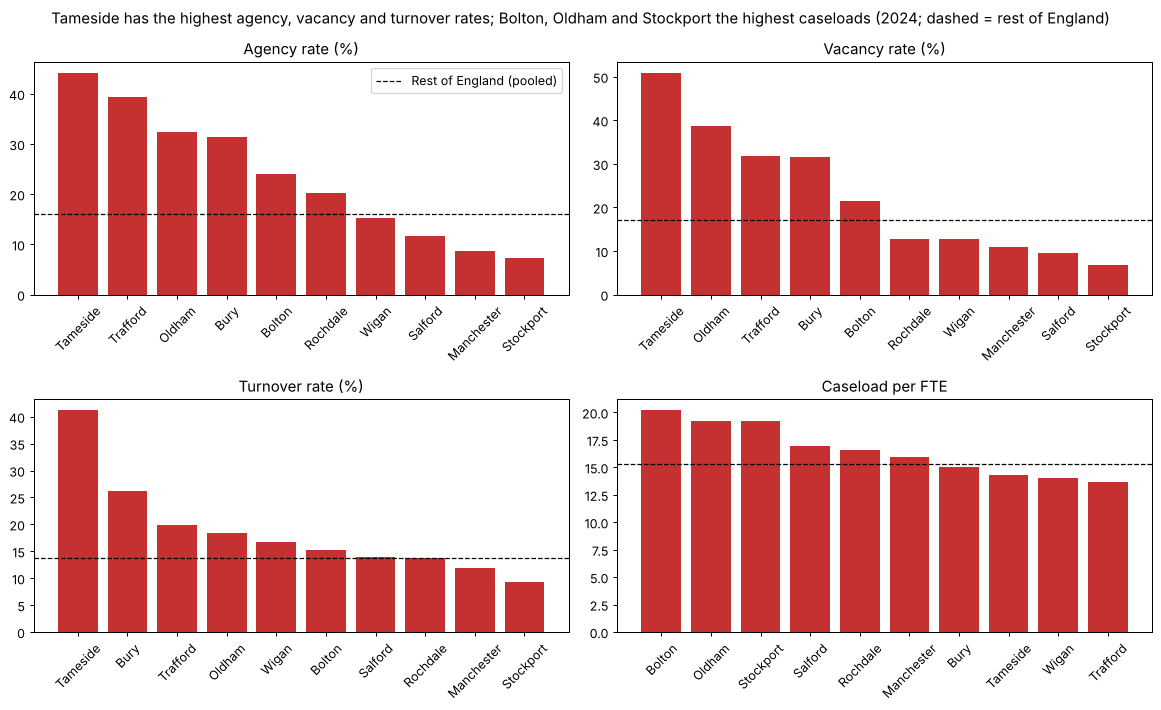

In [14]:
wf_cols = ["agency_rate_fte", "vacancy_rate_fte", "turnover_rate_fte", "caseload_fte"]
wf_labels = {"agency_rate_fte": "Agency rate (%)", "vacancy_rate_fte": "Vacancy rate (%)",
             "turnover_rate_fte": "Turnover rate (%)", "caseload_fte": "Caseload per FTE"}

wf = gm[["inpost_fte"] + wf_cols].rename(columns=wf_labels | {"inpost_fte": "Social workers in post (FTE)"})
display(wf.sort_values("Agency rate (%)", ascending=False).round(1))
summary = gm[wf_cols].agg(["mean", "median", "std", "min", "max"]).T
summary["IQR"] = gm[wf_cols].quantile(0.75) - gm[wf_cols].quantile(0.25)
display(summary.rename(index=wf_labels).round(2))

eng_benchmark = pooled(y24[~y24.is_gm])
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.flat, wf_cols):
    s = gm[col].sort_values(ascending=False)
    ax.bar(s.index, s.values, color=GM_COLOR)
    ax.axhline(eng_benchmark[wf_labels[col]], ls="--", color="black", lw=1, label="Rest of England (pooled)")
    ax.set_title(wf_labels[col]); ax.tick_params(axis="x", rotation=45)
axes[0, 0].legend()
plt.suptitle(f"Tameside has the highest agency, vacancy and turnover rates; Bolton, Oldham and Stockport the highest caseloads ({PROFILE_YEAR}; dashed = rest of England)", fontsize=12)
plt.tight_layout(); plt.show()

### 5.1 Relationships between Indicators

**Why.** If several indicators move together, they may describe one underlying problem rather than several. This matters for the profiles (Section 6) and for the models (Sections 7–9), where strongly correlated predictors can make estimates unstable.

**Method.** Pearson and Spearman (rank) correlations across the ten authorities. Tameside is an extreme case, so the correlations are recalculated without it as a sensitivity check.

Pearson (n = 10)
                   Agency rate (%)  Vacancy rate (%)  Turnover rate (%)  Caseload per FTE
Agency rate (%)               1.00              0.95               0.82             -0.35
Vacancy rate (%)              0.95              1.00               0.87             -0.25
Turnover rate (%)             0.82              0.87               1.00             -0.50
Caseload per FTE             -0.35             -0.25              -0.50              1.00
Spearman (n = 10)
                   Agency rate (%)  Vacancy rate (%)  Turnover rate (%)  Caseload per FTE
Agency rate (%)               1.00              0.97               0.90             -0.36
Vacancy rate (%)              0.97              1.00               0.89             -0.32
Turnover rate (%)             0.90              0.89               1.00             -0.52
Caseload per FTE             -0.36             -0.32              -0.52              1.00
Pearson without Tameside (n = 9)
                   Agency rate (

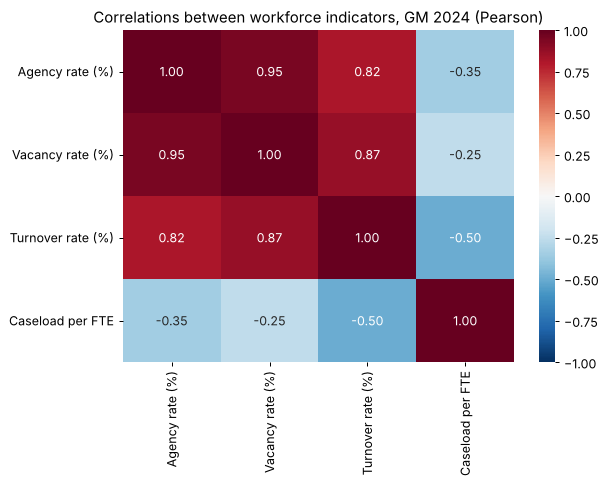

In [15]:
pearson = gm[wf_cols].corr(method="pearson").rename(index=wf_labels, columns=wf_labels)
spearman = gm[wf_cols].corr(method="spearman").rename(index=wf_labels, columns=wf_labels)
no_tameside = gm.drop("Tameside")[wf_cols].corr().rename(index=wf_labels, columns=wf_labels)
print("Pearson (n = 10)"); display(pearson.round(2))
print("Spearman (n = 10)"); display(spearman.round(2))
print("Pearson without Tameside (n = 9)"); display(no_tameside.round(2))

plt.figure(figsize=(7, 5.5))
sns.heatmap(pearson, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlations between workforce indicators, GM 2024 (Pearson)")
plt.tight_layout(); plt.show()

### Findings: Variation within GM

- **The ten authorities face very different conditions.** Agency rates range from 7% (Stockport) to 44% (Tameside), vacancy rates from 7% (Stockport) to 51% (Tameside), and caseloads from 13.7 (Trafford) to 20.2 (Bolton).
- **Agency, vacancy and turnover move together.** Their correlations are between 0.82 and 0.95 (Pearson) and remain high without Tameside (0.78–0.93). They describe one underlying problem: **workforce instability**.
- **Caseload behaves differently.** It is negatively correlated with turnover (r ≈ −0.50). Authorities with high caseloads are not the same as those with unstable workforces.

**Business implication (O2/O3).** GM is not one market but at least two: authorities with **unstable workforces** and authorities with **heavy workloads**. They have different problems, so DialogXR needs different value propositions for each.

*Note:* with only ten authorities, these correlations are descriptive. Sections 7–9 test the relationships on the national dataset.

## 6. Operational Pressure Profiles for GM (O3)

**Why.** The indicators are on different scales (percentages, cases, £000), so they cannot be compared directly. Standardising them shows where each authority sits relative to the GM average on each dimension, which turns the descriptive data into a profile for each authority.

**Indicators and domains**
- **Financial intensity:** CSC net spend per case (£000)
- **Workload pressure:** caseload per FTE
- **Workforce pressure:** agency rate, vacancy rate, turnover rate

All five are aligned so that a higher value means more pressure. No overall score is calculated: the three workforce indicators are strongly correlated (Section 5.1), so adding them up would give workforce pressure three times the weight.

In [16]:
profile_cols = ["spend_per_case", "caseload_fte", "agency_rate_fte", "vacancy_rate_fte", "turnover_rate_fte"]
profile_labels = ["Financial intensity", "Caseload pressure", "Agency rate", "Vacancy rate", "Turnover"]
model_data = gm[profile_cols].copy()
display(model_data.round(2))

print("\nOutlier check (1.5 × IQR rule):")
for col in profile_cols:
    q1, q3 = model_data[col].quantile([0.25, 0.75]); iqr = q3 - q1
    flagged = model_data[(model_data[col] < q1 - 1.5 * iqr) | (model_data[col] > q3 + 1.5 * iqr)][col]
    print(f"  {col}: bounds {q1 - 1.5*iqr:.2f} to {q3 + 1.5*iqr:.2f} | flagged: {flagged.round(2).to_dict() or 'none'}")

            spend_per_case  caseload_fte  agency_rate_fte  vacancy_rate_fte  turnover_rate_fte
la_name                                                                                       
Bolton               44.20          20.2             24.0              21.4               15.2
Bury                 30.76          15.0             31.5              31.5               26.2
Manchester           46.27          15.9              8.7              10.9               11.9
Oldham               29.02          19.2             32.3              38.7               18.3
Rochdale             35.54          16.6             20.3              12.7               13.7
Salford              34.08          16.9             11.6               9.5               13.9
Stockport            31.49          19.2              7.3               6.9                9.2
Tameside             43.73          14.3             44.2              50.9               41.2
Trafford             44.05          13.7          

Rank correlation between z-score and robust profiles: {'Financial intensity': 1.0, 'Caseload pressure': 1.0, 'Agency rate': 1.0, 'Vacancy rate': 1.0, 'Turnover': 1.0}


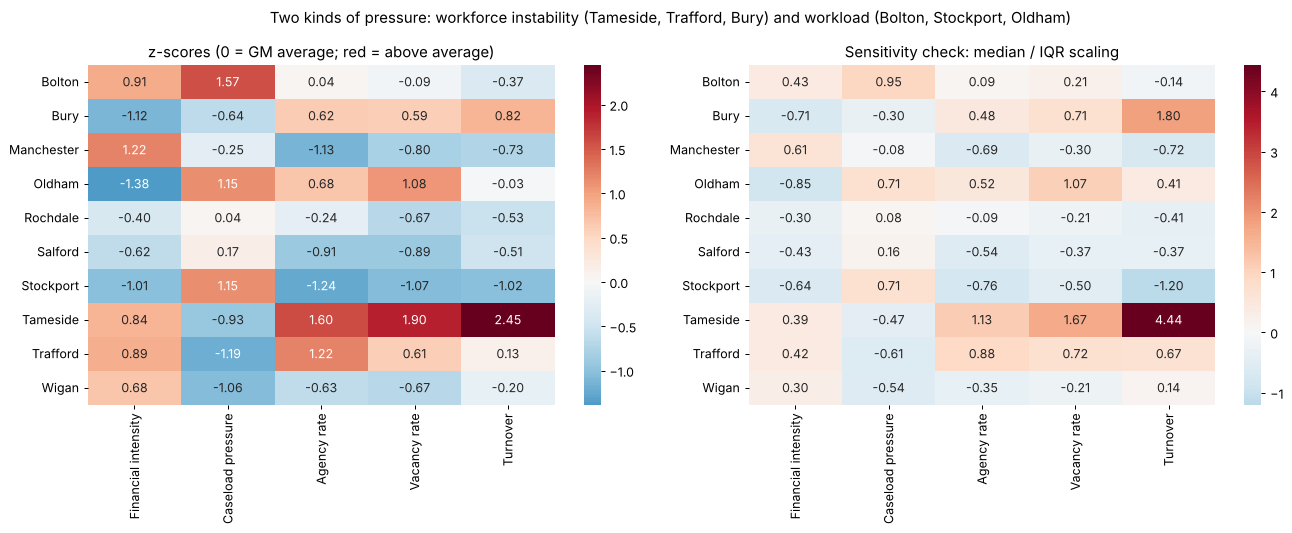

In [17]:
z = (model_data - model_data.mean()) / model_data.std()
z.columns = profile_labels
robust = (model_data - model_data.median()) / (model_data.quantile(0.75) - model_data.quantile(0.25))
robust.columns = profile_labels

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0])
plt.suptitle("Two kinds of pressure: workforce instability (Tameside, Trafford, Bury) and workload (Bolton, Stockport, Oldham)", fontsize=12)
axes[0].set_title("z-scores (0 = GM average; red = above average)")
sns.heatmap(robust, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Sensitivity check: median / IQR scaling")
for ax in axes: ax.set_ylabel("")
plt.tight_layout(); plt.show()

rank_check = pd.Series({lab: stats.spearmanr(z[lab], robust[lab])[0] for lab in profile_labels})
print("Rank correlation between z-score and robust profiles:", rank_check.round(2).to_dict())

### Findings: Pressure Profiles

- **Tameside** is the clearest case of workforce instability: the highest agency, vacancy and turnover values in GM (z-scores between 1.6 and 2.5), and flagged as an outlier for turnover (41.2%). It is kept in the analysis because these are real, observed values.
- **Trafford** and **Bury** also show above-average workforce pressure (Trafford mainly through agency use). Trafford combines it with high financial intensity.
- **Bolton**, **Oldham** and **Stockport** show above-average caseload pressure. Oldham also had high vacancy pressure in 2024.
- **Manchester** has the highest financial intensity but a relatively stable workforce. **Salford** and **Rochdale** are close to or below average on most indicators.
- The robust (median/IQR) scaling gives the same ordering for every indicator, so the profiles do not depend on the scaling method.

**Business implication (O3).** Three provisional segments emerge: **workforce instability** (Tameside, Trafford, Bury), **workload pressure** (Bolton, Stockport, Oldham) and **stable, high-spend** (Manchester, Wigan). These are descriptive profiles based on ten authorities. Sections 7–10 test them against a national model.

## 7. Model 1 (Inference): Is Workforce Pressure Associated with Higher Expenditure?

**Question.** Holding case volume constant, do authorities with more agency use, vacancies or turnover spend more on CSC? If yes, Bikal would have a direct financial argument (DialogXR reduces costs).

**Why a national model.** Ten authorities are too few for a multiple regression with several predictors. The model is estimated on all English upper-tier authorities (about 140 with complete data).

**Specification.** Ordinary least squares (OLS):

$$\log(\text{CSC net expenditure}) = \beta_0 + \beta_1 \log(\text{cases}) + \beta_2\,\text{agency} + \beta_3\,\text{vacancy} + \beta_4\,\text{turnover} + \beta_5\,\text{caseload} + \beta_6\,\text{absence} + \beta_7\,\text{Inner London} + \beta_8\,\text{Outer London} + \varepsilon$$

- **Log outcome:** spending is right-skewed and grows with authority size; coefficients read approximately as percentage differences.
- **log(cases)** controls for scale and demand.
- **London indicators** control for higher London costs.
- **HC3 robust standard errors** protect against unequal error variance.
- **Variance inflation factors (VIF)** check multicollinearity.
- **Sensitivity check:** RO3 covers April 2023 – March 2024. The primary model uses CSWW 2024 for consistency with Sections 4–6; CSWW 2023 (snapshot inside the financial year) is used as a check.

In [18]:
def ols_hc3(y, X, names):
    X = np.column_stack([np.ones(len(X)), X]); n, k = X.shape
    b = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ b
    XtXi = np.linalg.inv(X.T @ X)
    h = np.einsum("ij,jk,ik->i", X, XtXi, X)
    V = XtXi @ (X.T * (e**2 / (1 - h)**2)) @ X @ XtXi
    se = np.sqrt(np.diag(V)); t = b / se; p = 2 * stats.t.sf(np.abs(t), n - k)
    r2 = 1 - (e @ e) / ((y - y.mean()) @ (y - y.mean()))
    adj = 1 - (1 - r2) * (n - 1) / (n - k)
    table = pd.DataFrame({"coef": b, "se (HC3)": se, "t": t, "p-value": p}, index=["const"] + names)
    return table, r2, adj, n

def vif(X, names):
    out = {}
    for i, nm in enumerate(names):
        y = X[:, i]; others = np.column_stack([np.ones(len(X)), np.delete(X, i, 1)])
        b = np.linalg.lstsq(others, y, rcond=None)[0]; e = y - others @ b
        out[nm] = 1 / ((e @ e) / ((y - y.mean()) @ (y - y.mean())))
    return pd.Series(out, name="VIF")

m1_vars = ["log_cases", "agency_rate_fte", "vacancy_rate_fte", "turnover_rate_fte",
           "caseload_fte", "absence_rate_fte", "inner_london", "outer_london"]

def model1_data(year):
    d = integrate(year)
    d["log_spend"] = np.log(d["csc_net"]); d["log_cases"] = np.log(d["cases"])
    d["inner_london"] = (d.region_name == "Inner London").astype(int)
    d["outer_london"] = (d.region_name == "Outer London").astype(int)
    return d.dropna(subset=m1_vars + ["log_spend"])

m1 = {}
for year in [2024, 2023]:
    d = model1_data(year)
    table, r2, adj, n = ols_hc3(d["log_spend"].values, d[m1_vars].values, m1_vars)
    m1[year] = table
    label = "primary" if year == 2024 else "sensitivity"
    print(f"\nModel 1 ({label}) | CSWW {year} | n = {n} | R² = {r2:.3f} | adjusted R² = {adj:.3f}")
    display(table.round(4))
    if year == 2024:
        display(vif(d[m1_vars].values, m1_vars).round(2).to_frame().T)


Model 1 (primary) | CSWW 2024 | n = 143 | R² = 0.856 | adjusted R² = 0.847
                     coef  se (HC3)        t  p-value
const              4.9757    0.3340  14.8973   0.0000
log_cases          0.9650    0.0402  24.0096   0.0000
agency_rate_fte   -0.0038    0.0035  -1.1005   0.2731
vacancy_rate_fte   0.0063    0.0036   1.7414   0.0839
turnover_rate_fte  0.0018    0.0042   0.4323   0.6662
caseload_fte      -0.0629    0.0112  -5.5990   0.0000
absence_rate_fte  -0.0040    0.0179  -0.2224   0.8243
inner_london      -0.0089    0.0730  -0.1218   0.9032
outer_london      -0.0238    0.0708  -0.3365   0.7370
     log_cases  agency_rate_fte  vacancy_rate_fte  turnover_rate_fte  caseload_fte  absence_rate_fte  inner_london  outer_london
VIF       1.34              4.4              4.92               1.51          1.29              1.18          1.23          1.14

Model 1 (sensitivity) | CSWW 2023 | n = 141 | R² = 0.864 | adjusted R² = 0.856
                     coef  se (HC3)        t  

**Model 1 diagnostics.** OLS assumes a linear relationship, errors with constant variance and no single observation driving the result. These are checked with a residuals-versus-fitted plot, a Q-Q plot of the residuals, a Breusch–Pagan test for heteroskedasticity and Cook's distance for influential observations.

Breusch–Pagan LM = 18.46, p = 0.018
Shapiro–Wilk on residuals: p = 0.392
Observations with Cook's distance > 4/n (0.028): 11
                          Cook's distance
Hillingdon                          0.112
Havering                            0.090
Lambeth                             0.072
Herefordshire, County of            0.061
Harrow                              0.058

Model 1 without influential observations | n = 132 | R² = 0.899
                     coef  se (HC3)       t  p-value
agency_rate_fte   -0.0027    0.0031 -0.8658   0.3883
vacancy_rate_fte   0.0037    0.0030  1.2405   0.2172
turnover_rate_fte  0.0070    0.0037  1.8990   0.0599
caseload_fte      -0.0593    0.0095 -6.2172   0.0000


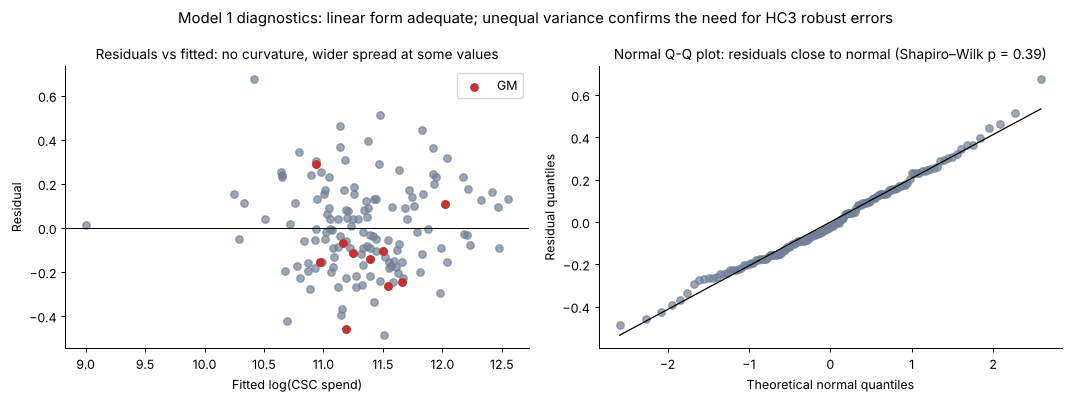

In [19]:
d_m1 = model1_data(2024)
X_m1 = np.column_stack([np.ones(len(d_m1)), d_m1[m1_vars].values]); y_m1 = d_m1["log_spend"].values
b_m1 = np.linalg.lstsq(X_m1, y_m1, rcond=None)[0]; fitted_m1 = X_m1 @ b_m1; resid_m1 = y_m1 - fitted_m1
n_m1, k_m1 = X_m1.shape
# Breusch–Pagan (LM = n × R² of squared residuals on X)
g = np.linalg.lstsq(X_m1, resid_m1**2, rcond=None)[0]; e2 = resid_m1**2 - X_m1 @ g
r2_bp = 1 - (e2 @ e2) / (((resid_m1**2) - (resid_m1**2).mean()) @ ((resid_m1**2) - (resid_m1**2).mean()))
bp_lm = n_m1 * r2_bp; bp_p = stats.chi2.sf(bp_lm, k_m1 - 1)
# Cook's distance
H = X_m1 @ np.linalg.inv(X_m1.T @ X_m1) @ X_m1.T; h = np.diag(H); s2 = (resid_m1 @ resid_m1) / (n_m1 - k_m1)
cooks = (resid_m1**2 / (k_m1 * s2)) * h / (1 - h)**2
infl = pd.Series(cooks, index=d_m1.la_name.values).sort_values(ascending=False)
print(f"Breusch–Pagan LM = {bp_lm:.2f}, p = {bp_p:.3f}")
print(f"Shapiro–Wilk on residuals: p = {stats.shapiro(resid_m1).pvalue:.3f}")
print(f"Observations with Cook's distance > 4/n ({4/n_m1:.3f}): {int((cooks > 4/n_m1).sum())}")
display(infl.head(5).round(3).rename("Cook's distance").to_frame())

# Re-estimate without the influential observations
keep = cooks <= 4 / n_m1
t_robust, r2_r, _, n_r = ols_hc3(y_m1[keep], d_m1[m1_vars].values[keep], m1_vars)
print(f"\nModel 1 without influential observations | n = {n_r} | R² = {r2_r:.3f}")
display(t_robust.loc[["agency_rate_fte", "vacancy_rate_fte", "turnover_rate_fte", "caseload_fte"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(fitted_m1, resid_m1, color=ENG_COLOR, alpha=0.7)
axes[0].scatter(fitted_m1[d_m1.is_gm.values], resid_m1[d_m1.is_gm.values], color=GM_COLOR, label="GM")
axes[0].axhline(0, color="black", lw=0.8); axes[0].set_xlabel("Fitted log(CSC spend)"); axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs fitted: no curvature, wider spread at some values", fontsize=11); axes[0].legend()
(osm, osr), (slope, intercept, _) = stats.probplot(resid_m1, dist="norm")
axes[1].scatter(osm, osr, color=ENG_COLOR, alpha=0.7)
axes[1].plot(osm, slope * osm + intercept, color="black", lw=1)
axes[1].set_xlabel("Theoretical normal quantiles"); axes[1].set_ylabel("Residual quantiles")
axes[1].set_title(f"Normal Q-Q plot: residuals close to normal (Shapiro–Wilk p = {stats.shapiro(resid_m1).pvalue:.2f})", fontsize=11)
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Model 1 diagnostics: linear form adequate; unequal variance confirms the need for HC3 robust errors", fontsize=12)
plt.tight_layout(); plt.show()

**Findings: diagnostics.** The residuals-versus-fitted plot shows no curvature, so the log-linear form is adequate. The Breusch–Pagan test rejects constant variance (LM = 18.5, p = 0.018), which confirms that HC3 robust standard errors are needed. The residuals are consistent with normality (Shapiro–Wilk p = 0.39). Eleven authorities exceed the Cook's distance threshold of 4/n, led by Hillingdon, Havering and Lambeth. Re-estimating without them leaves the conclusions unchanged: agency and vacancy remain non-significant, turnover remains non-significant at 5% (p = 0.06) and caseload remains negative and significant. Model 1's result is therefore not driven by a few unusual authorities.

### 7.1 How Large an Effect Can Be Ruled Out?

**Why.** A non-significant coefficient does not show that there is no effect. The 95% confidence intervals show which effect sizes the data are still compatible with, and a joint test checks whether the three instability indicators together add explanatory power. Coefficients are converted to the percentage change in spending associated with a 10-point higher rate.

In [20]:
d = model1_data(2024)
y = d["log_spend"].values; X = np.column_stack([np.ones(len(d)), d[m1_vars].values]); n, k = X.shape
b = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ b; XtXi = np.linalg.inv(X.T @ X)
h = np.einsum("ij,jk,ik->i", X, XtXi, X); V = XtXi @ (X.T * (e**2 / (1 - h)**2)) @ X @ XtXi
tcrit = stats.t.ppf(0.975, n - k)
rows = {}
for v in ["agency_rate_fte", "vacancy_rate_fte", "turnover_rate_fte"]:
    j = 1 + m1_vars.index(v); lo, hi = b[j] - tcrit * np.sqrt(V[j, j]), b[j] + tcrit * np.sqrt(V[j, j])
    rows[wf_labels.get(v, v)] = {"Change in spend per +10 pts (%)": (np.exp(10 * b[j]) - 1) * 100,
                                 "95% CI low (%)": (np.exp(10 * lo) - 1) * 100, "95% CI high (%)": (np.exp(10 * hi) - 1) * 100}
c = np.zeros(k); c[1 + m1_vars.index("agency_rate_fte")] = 10; c[1 + m1_vars.index("vacancy_rate_fte")] = 10
est, se_c = c @ b, np.sqrt(c @ V @ c)
rows["Agency and vacancy both +10 pts"] = {"Change in spend per +10 pts (%)": (np.exp(est) - 1) * 100,
                                          "95% CI low (%)": (np.exp(est - tcrit * se_c) - 1) * 100,
                                          "95% CI high (%)": (np.exp(est + tcrit * se_c) - 1) * 100}
display(pd.DataFrame(rows).T.round(1))
idx = [1 + m1_vars.index(v) for v in ["agency_rate_fte", "vacancy_rate_fte", "turnover_rate_fte"]]
W = b[idx] @ np.linalg.solve(V[np.ix_(idx, idx)], b[idx])
print(f"Joint test (agency, vacancy, turnover = 0), HC3: F(3, {n - k}) = {W / 3:.2f}, p = {stats.f.sf(W / 3, 3, n - k):.3f}")

                                 Change in spend per +10 pts (%)  95% CI low (%)  95% CI high (%)
Agency rate (%)                                             -3.8           -10.2              3.1
Vacancy rate (%)                                             6.5            -0.9             14.5
Turnover rate (%)                                            1.8            -6.2             10.5
Agency and vacancy both +10 pts                              2.5            -2.0              7.2
Joint test (agency, vacancy, turnover = 0), HC3: F(3, 134) = 1.44, p = 0.233


### Findings: Effect Sizes Ruled Out

- The three instability indicators are not jointly significant (p ≈ 0.23).
- For agency use, the data rule out a large positive association: a 10-point higher agency rate is associated with between about −10% and +3% spending.
- For vacancies, the interval is wider (about −1% to +14%), so a moderate positive association cannot be excluded.
- The H1 verdict is therefore *not supported*, not *disproved*: the data do not support a cost argument based on total spending, but they cannot exclude a moderate vacancy effect or an effect on staffing costs specifically.

**Checking a ratio used in the earlier draft.** An earlier version of this analysis used *spend per in-post social worker* and found a strong correlation with agency dependency in GM. That ratio divides by in-post staff only. Authorities that rely on agency workers have fewer in-post staff for the same total workforce, so the ratio rises mechanically. The check below divides by the **total** workforce (in-post + agency) instead.

In [21]:
d = integrate(PROFILE_YEAR)
d["spend_per_inpost_sw"] = d.csc_net / d.inpost_fte
d["spend_per_total_workforce"] = d.csc_net / (d.inpost_fte + d.agency_fte)
check = pd.DataFrame({
    f"England (n={d[['spend_per_inpost_sw','agency_rate_fte']].dropna().shape[0]})": [
        d[["spend_per_inpost_sw", "agency_rate_fte"]].corr().iloc[0, 1],
        d[["spend_per_total_workforce", "agency_rate_fte"]].corr().iloc[0, 1]],
    "GM only (n=10)": [
        d[d.is_gm][["spend_per_inpost_sw", "agency_rate_fte"]].corr().iloc[0, 1],
        d[d.is_gm][["spend_per_total_workforce", "agency_rate_fte"]].corr().iloc[0, 1]],
}, index=["Spend per in-post social worker vs agency rate", "Spend per total workforce vs agency rate"])
display(check.round(2))

                                                England (n=144)  GM only (n=10)
Spend per in-post social worker vs agency rate             0.64            0.83
Spend per total workforce vs agency rate                   0.08            0.25


### Findings: Model 1

- The model explains about **86%** of the variation in CSC expenditure (R² ≈ 0.86). Almost all of it comes from scale: the log(cases) coefficient is close to 1, so spending rises roughly in proportion to case volume.
- **In the primary (2024) model, after controlling for case volume, none of the workforce instability indicators (agency, vacancy, turnover) or absence is significantly associated with expenditure at the 5% level.** Vacancy is borderline in 2024 (p ≈ 0.08) but clearly not significant in 2023 (p ≈ 0.61). Turnover is significant in the 2023 check (p ≈ 0.04) but not in 2024 (p ≈ 0.67). Neither result is robust across years.
- **Caseload is negative and significant in both years** (about 5–6% lower spending per extra case per worker). Authorities with fewer staff per case spend less.
- Agency and vacancy rates have VIFs of about 5, confirming the multicollinearity seen in GM.
- **The earlier spend-per-social-worker correlation is mainly a denominator effect.** Nationally, the correlation with agency rate falls from 0.64 to 0.08 when spending is divided by the total workforce instead of in-post staff. In GM it falls from 0.83 to 0.25, which is not meaningful with ten authorities.

**Business implication.** The available financial data **do not support** a claim that workforce instability is associated with higher CSC spending. Bikal should not lead with a "DialogXR reduces agency costs" argument. This negative result is useful: it removes a weak argument and points the value proposition towards workload and workforce stability (Model 2).

*Note:* RO3 does not separate agency staff costs, and more than half of CSC spending is on placements. An agency cost premium could exist but be too small to detect in total CSC spending.

## 8. Model 2 (Prediction): Can Current Indicators Predict Next Year's Workforce Pressure?

**Question.** Using an authority's indicators this year, can we predict its agency and vacancy rates next year? For Bikal, this is an **early-warning and market-prioritisation tool** that works for any region in England.

**Data.** National panel, 2017–2025. Each observation pairs an authority's indicators in year *t* with its outcome in year *t+1*, which gives about 1,150 observations.

- **Outcomes (Y):** next year's agency rate, vacancy rate and turnover rate
- **Predictors (X), year t:** agency rate, vacancy rate, turnover rate, caseload, absence rate, starter rate, London indicator

**Evaluation design**
- **Temporal split:** train on outcomes for 2018–2023, test on outcomes for 2024–2025. The model is always tested on later years than it was trained on, as in real use.
- **Baselines:** (a) last year's value (persistence) and (b) the training mean. A useful model must beat persistence.
- **Models:** OLS, Ridge (L2 penalty) and Lasso (L1 penalty), with standardised predictors. Regularisation is used because agency and vacancy rates are strongly correlated. Penalty strength is chosen by cross-validation; Lasso folds are grouped by authority so that the same authority never appears in both training and validation folds.
- **Metrics:** mean absolute error (MAE), root mean squared error (RMSE) and out-of-sample R².

   Outcome (next year)                        Model    MAE   RMSE  R² (test)  n train  n test
0      Agency rate (%)  Baseline: last year's value  4.390  6.117      0.619      864     284
1      Agency rate (%)      Baseline: training mean  8.276  9.940     -0.007      864     284
2      Agency rate (%)                          OLS  4.024  5.423      0.700      864     284
3      Agency rate (%)                        Ridge  4.023  5.419      0.701      864     284
4      Agency rate (%)                        Lasso  4.052  5.438      0.699      864     284
5     Vacancy rate (%)  Baseline: last year's value  4.929  6.760      0.539      868     285
6     Vacancy rate (%)      Baseline: training mean  8.062  9.985     -0.005      868     285
7     Vacancy rate (%)                          OLS  4.659  6.101      0.625      868     285
8     Vacancy rate (%)                        Ridge  4.657  6.084      0.627      868     285
9     Vacancy rate (%)                        Lasso  4.704  

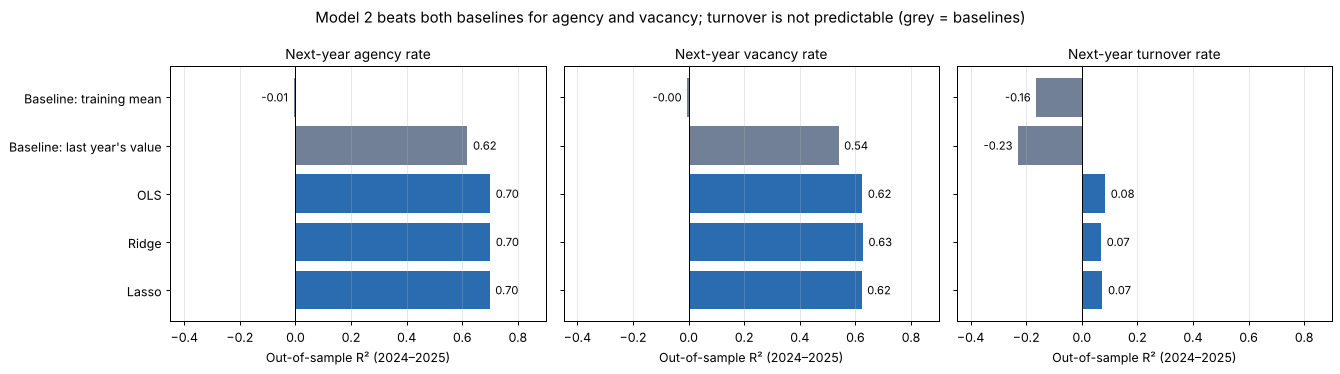

In [22]:
m2_feats = ["agency_rate_fte", "vacancy_rate_fte", "turnover_rate_fte", "caseload_fte",
            "absence_rate_fte", "starter_rate", "london"]
panel = csww.sort_values(["new_la_code", "time_period"]).copy()

def make_panel(target):
    p = panel.copy()
    p["y_next"] = p.groupby("new_la_code")[target].shift(-1)
    p["year_next"] = p.groupby("new_la_code")["time_period"].shift(-1)
    p = p.dropna(subset=m2_feats + ["y_next"])
    return p[p.year_next == p.time_period + 1].copy()

results, fitted = [], {}
for target in ["agency_rate_fte", "vacancy_rate_fte", "turnover_rate_fte"]:
    p = make_panel(target)
    train, test = p[p.year_next <= 2023], p[p.year_next >= 2024]
    preds = {"Baseline: last year's value": test[target].values,
             "Baseline: training mean": np.full(len(test), train.y_next.mean())}
    splits = list(GroupKFold(n_splits=5).split(train[m2_feats], train.y_next, train.new_la_code))
    models = {"OLS": LinearRegression(),
              "Ridge": RidgeCV(alphas=np.logspace(-3, 3, 50)),
              "Lasso": LassoCV(cv=splits, max_iter=50000)}
    for name, mdl in models.items():
        pipe = make_pipeline(StandardScaler(), mdl).fit(train[m2_feats], train.y_next)
        preds[name] = pipe.predict(test[m2_feats]); fitted[(target, name)] = pipe
    for name, pr in preds.items():
        results.append({"Outcome (next year)": wf_labels[target], "Model": name,
                        "MAE": mean_absolute_error(test.y_next, pr),
                        "RMSE": mean_squared_error(test.y_next, pr) ** 0.5,
                        "R² (test)": r2_score(test.y_next, pr),
                        "n train": len(train), "n test": len(test)})
results = pd.DataFrame(results)
display(results.round(3))

model_order = ["Baseline: training mean", "Baseline: last year's value", "OLS", "Ridge", "Lasso"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, target in zip(axes, ["Agency rate (%)", "Vacancy rate (%)", "Turnover rate (%)"]):
    sub = results[results["Outcome (next year)"] == target].set_index("Model")["R² (test)"].reindex(model_order)
    colors = [ENG_COLOR if m.startswith("Baseline") else "#2b6cb0" for m in sub.index]
    ax.barh(sub.index, sub.values, color=colors)
    for y, v in enumerate(sub.values):
        ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:.2f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=9)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlim(-0.45, 0.9); ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"Next-year {target.split(' (')[0].lower()}", fontsize=11)
    ax.set_xlabel("Out-of-sample R² (2024–2025)")
axes[0].invert_yaxis()
plt.suptitle("Model 2 beats both baselines for agency and vacancy; turnover is not predictable (grey = baselines)")
plt.tight_layout(); plt.show()

lasso_coefs = pd.DataFrame({wf_labels[t]: pd.Series(fitted[(t, "Lasso")][-1].coef_, index=m2_feats)
                            for t in ["agency_rate_fte", "vacancy_rate_fte"]})
print("Lasso standardised coefficients:"); display(lasso_coefs.round(2))

**Benchmark against non-linear models.** To test whether the linear models leave predictive accuracy on the table, two tree-based ensemble methods are fitted on exactly the same training and test years: a Random Forest (500 trees, minimum 5 observations per leaf) and Gradient Boosting (histogram-based, depth 3, learning rate 0.05, 300 iterations).

In [23]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
bench = []
for target in ["agency_rate_fte", "vacancy_rate_fte"]:
    p = make_panel(target)
    train, test = p[p.year_next <= 2023], p[p.year_next >= 2024]
    candidates = {"Ridge (linear)": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))),
                  "Random Forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=5, random_state=0, n_jobs=-1),
                  "Gradient Boosting": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0)}
    for name, mdl in candidates.items():
        pr = mdl.fit(train[m2_feats], train.y_next).predict(test[m2_feats])
        bench.append({"Outcome (next year)": wf_labels[target], "Model": name,
                      "MAE": mean_absolute_error(test.y_next, pr), "RMSE": mean_squared_error(test.y_next, pr) ** 0.5,
                      "R² (test)": r2_score(test.y_next, pr)})
display(pd.DataFrame(bench).round(3))

  Outcome (next year)              Model    MAE   RMSE  R² (test)
0     Agency rate (%)     Ridge (linear)  4.023  5.419      0.701
1     Agency rate (%)      Random Forest  4.196  5.669      0.673
2     Agency rate (%)  Gradient Boosting  4.384  5.944      0.640
3    Vacancy rate (%)     Ridge (linear)  4.657  6.084      0.627
4    Vacancy rate (%)      Random Forest  4.857  6.388      0.589
5    Vacancy rate (%)  Gradient Boosting  5.052  6.611      0.559


### Findings: Model 2

- **Agency and vacancy pressure can be predicted a year ahead.** On the 2024–2025 test years, the models reach an out-of-sample R² of about **0.70 for agency rate** and **0.63 for vacancy rate**, with mean absolute errors of about 4–5 percentage points.
- **The models beat persistence.** Last year's value alone gives R² ≈ 0.62 (agency) and 0.54 (vacancy), so the other indicators add predictive information.
- **OLS, Ridge and Lasso perform almost identically.** With about 870 training observations and seven predictors, overfitting is not a problem. Lasso shrinks absence rate to (almost) zero, which matches its non-significance in Section 9.
- **The linear models also beat non-linear alternatives.** Random Forest (R² 0.67 agency, 0.59 vacancy) and Gradient Boosting (0.64, 0.56) perform worse than Ridge on the same test years. With seven predictors and a mostly linear, persistent signal, the extra flexibility of tree ensembles adds variance rather than accuracy, so the more interpretable linear models are preferred.
- **Turnover cannot be predicted** (R² ≈ 0.08). It changes from year to year in ways these indicators do not capture.

**Business implication (O3).** Bikal can use the agency and vacancy model as a transparent scoring tool to rank any English authority by expected workforce pressure next year. Turnover should be monitored but not used for targeting.

### 8.1 Where the Model Fails

**Why.** A predictive model is only useful if its users know where not to trust it. Test-set errors (2024–2025) are broken down by year, authority size, pressure level and for the GM authorities, using the Ridge model.

In [24]:
fail_tables = {}
for target in ["agency_rate_fte", "vacancy_rate_fte"]:
    p = make_panel(target)
    train, test = p[p.year_next <= 2023], p[p.year_next >= 2024].copy()
    pipe = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))).fit(train[m2_feats], train.y_next)
    test["pred"] = pipe.predict(test[m2_feats]); test["error"] = test.pred - test.y_next
    test["abs_error"] = test.error.abs(); test["persistence_abs_error"] = (test[target] - test.y_next).abs()
    test["size_quartile"] = pd.qcut(test.inpost_fte, 4, labels=["Smallest 25%", "Q2", "Q3", "Largest 25%"])
    test["level_quartile"] = pd.qcut(test[target], 4, labels=["Lowest 25%", "Q2", "Q3", "Highest 25%"])
    label = wf_labels[target]
    print(f"\n===== Next-year {label} =====")
    print("By test year (mean error > 0 = over-prediction):")
    display(test.groupby("year_next")[["abs_error", "persistence_abs_error", "error"]].mean().round(2))
    print("By authority size (in-post FTE):")
    display(test.groupby("size_quartile", observed=True)[["abs_error", "persistence_abs_error"]].mean().round(2))
    print("By current pressure level:")
    display(test.groupby("level_quartile", observed=True)[["abs_error", "persistence_abs_error", "error"]].mean().round(2))
    print(f"Errors above 10 points: {int((test.abs_error > 10).sum())} of {len(test)}")
    display(test.nlargest(5, "abs_error")[["la_name", "year_next", target, "y_next", "pred"]].round(1).reset_index(drop=True))
    gm_test = test[test.is_gm]
    print(f"GM authorities: MAE = {gm_test.abs_error.mean():.2f} (n = {len(gm_test)}) vs all authorities {test.abs_error.mean():.2f}")


===== Next-year Agency rate (%) =====
By test year (mean error > 0 = over-prediction):
           abs_error  persistence_abs_error  error
year_next                                         
2024.0          3.64                   4.03   1.02
2025.0          4.41                   4.75   2.84
By authority size (in-post FTE):
               abs_error  persistence_abs_error
size_quartile                                  
Smallest 25%        4.68                   5.51
Q2                  4.31                   4.83
Q3                  3.77                   3.81
Largest 25%         3.33                   3.42
By current pressure level:
                abs_error  persistence_abs_error  error
level_quartile                                         
Lowest 25%           2.69                   1.91   2.26
Q2                   4.00                   3.99   1.22
Q3                   4.28                   4.66   1.24
Highest 25%          5.14                   7.04   3.04
Errors above 10 points: 

### Findings: Where the Model Fails

- **Sudden shocks.** The largest errors are abrupt changes the model could not anticipate: Tameside's agency rate jumped from 24.3% to 44.2% in 2024 (predicted 23.0%), and Oldham's fell from 32.3% to 15.2% in 2025 (predicted 30.3%). The model mainly extends persistence, so it misses turning points.
- **System-wide change.** In 2025 the model over-predicted on average by about 3 percentage points for both outcomes (against about 1 point in 2024), because all indicators improved nationally in a way the training years did not contain.
- **Small authorities.** Errors are largest in the smallest quarter of authorities (agency MAE 4.7 against 3.3 for the largest quarter), where a few staff moving changes the rate sharply.
- **Low-pressure authorities.** For authorities in the lowest quarter of current pressure, the model is less accurate than simply carrying last year's value forward (agency MAE 2.7 against 1.9): it pulls low values towards the average. Its advantage over persistence is concentrated in the highest-pressure quarter (5.1 against 7.0), which is where Bikal's targeting decisions lie.
- **GM.** For the ten GM authorities the test MAE (about 5.1 agency, 5.8 vacancy) is above the national figure and above the 5-point target, mainly because of Tameside in 2024 and Oldham in 2025. Scores for individual GM authorities should therefore be read as broad bands, refreshed every year.

## 9. Explaining Model 2: Which Indicators Matter?

**Why.** A prediction is more useful to Bikal if it can be explained. This section estimates how much each indicator is associated with next year's pressure, with valid uncertainty.

**Method.** OLS on the full panel with:
- **Year fixed effects**, which absorb national changes that affect every authority in a given year (such as the general improvement in 2025);
- **Standard errors clustered by authority**, because repeated observations of the same authority are not independent.

Coefficients are in original units (percentage points per unit of the predictor) with 95% confidence intervals.


Outcome: next-year Agency rate (%) | n = 1148 | authorities = 157 | R² = 0.718
                    coef  se (clustered)  p-value  95% CI low  95% CI high
agency_rate_fte    0.776           0.034    0.000       0.709        0.843
vacancy_rate_fte   0.031           0.035    0.375      -0.037        0.099
turnover_rate_fte  0.062           0.036    0.090      -0.009        0.133
caseload_fte       0.405           0.080    0.000       0.248        0.563
absence_rate_fte   0.055           0.117    0.638      -0.174        0.284
starter_rate      -0.068           0.027    0.013      -0.121       -0.015
london             1.541           0.496    0.002       0.569        2.512

Outcome: next-year Vacancy rate (%) | n = 1153 | authorities = 157 | R² = 0.670
                    coef  se (clustered)  p-value  95% CI low  95% CI high
agency_rate_fte    0.301           0.041    0.000       0.220        0.381
vacancy_rate_fte   0.483           0.045    0.000       0.395        0.571
turnover_rate_

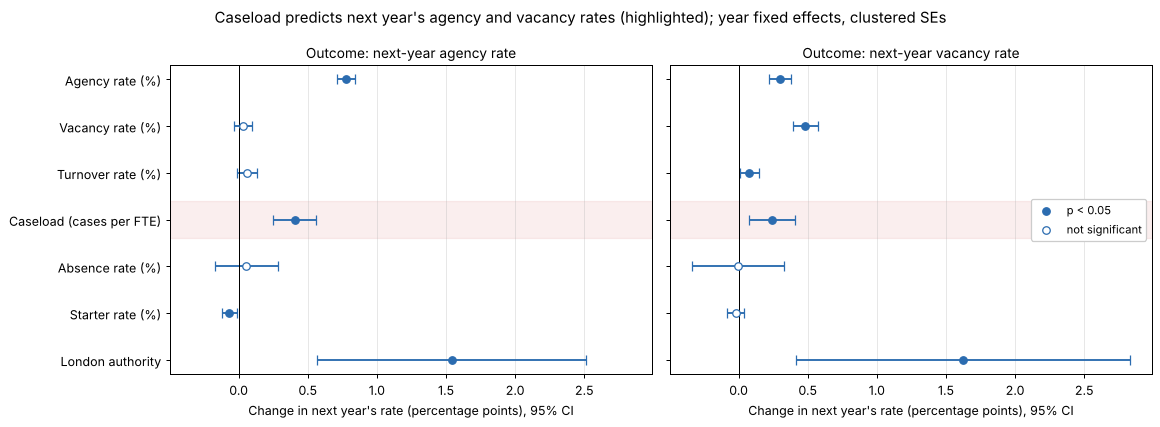

In [25]:
def ols_clustered(y, X, groups, names):
    X = np.column_stack([np.ones(len(X)), X]); n, k = X.shape
    b = np.linalg.lstsq(X, y, rcond=None)[0]; e = y - X @ b
    XtXi = np.linalg.inv(X.T @ X); meat = np.zeros((k, k)); G = 0
    for g in np.unique(groups):
        idx = groups == g; s = X[idx].T @ e[idx]; meat += np.outer(s, s); G += 1
    V = (G / (G - 1)) * ((n - 1) / (n - k)) * XtXi @ meat @ XtXi
    se = np.sqrt(np.diag(V)); p = 2 * stats.t.sf(np.abs(b / se), G - 1)
    r2 = 1 - (e @ e) / ((y - y.mean()) @ (y - y.mean()))
    t = pd.DataFrame({"coef": b, "se (clustered)": se, "p-value": p,
                      "95% CI low": b - 1.96 * se, "95% CI high": b + 1.96 * se}, index=["const"] + names)
    return t, r2, n, G

inference = {}
for target in ["agency_rate_fte", "vacancy_rate_fte"]:
    p = make_panel(target)
    year_fe = pd.get_dummies(p.time_period, prefix="year", drop_first=True).astype(float)
    t, r2, n, G = ols_clustered(p.y_next.values, np.column_stack([p[m2_feats].values, year_fe.values]),
                                p.new_la_code.values, m2_feats + list(year_fe.columns))
    inference[target] = t.loc[m2_feats]
    print(f"\nOutcome: next-year {wf_labels[target]} | n = {n} | authorities = {G} | R² = {r2:.3f}")
    display(t.loc[m2_feats].round(3))

nice = {"agency_rate_fte": "Agency rate (%)", "vacancy_rate_fte": "Vacancy rate (%)",
        "turnover_rate_fte": "Turnover rate (%)", "caseload_fte": "Caseload (cases per FTE)",
        "absence_rate_fte": "Absence rate (%)", "starter_rate": "Starter rate (%)", "london": "London authority"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, sharex=True)
for ax, target in zip(axes, ["agency_rate_fte", "vacancy_rate_fte"]):
    t = inference[target]
    labels = [nice[v] for v in t.index]; ypos = np.arange(len(t))
    sig = t["p-value"] < 0.05
    ax.errorbar(t["coef"], ypos, xerr=1.96 * t["se (clustered)"], fmt="none", ecolor="#2b6cb0", capsize=4)
    ax.scatter(t["coef"][sig], ypos[sig.values], color="#2b6cb0", zorder=3, label="p < 0.05")
    ax.scatter(t["coef"][~sig], ypos[~sig.values], facecolors="white", edgecolors="#2b6cb0", zorder=3, label="not significant")
    cl = list(t.index).index("caseload_fte")
    ax.axhspan(cl - 0.4, cl + 0.4, color=GM_COLOR, alpha=0.08)
    ax.set_yticks(ypos); ax.set_yticklabels(labels)
    ax.axvline(0, color="black", lw=0.8); ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"Outcome: next-year {wf_labels[target].split(' (')[0].lower()}", fontsize=11)
    ax.set_xlabel("Change in next year's rate (percentage points), 95% CI")
axes[0].invert_yaxis(); axes[1].legend(loc="center right", fontsize=9, framealpha=1)
plt.suptitle("Caseload predicts next year's agency and vacancy rates (highlighted); year fixed effects, clustered SEs")
plt.tight_layout(); plt.show()

### Findings: Which Indicators Matter

- **Workforce pressure is persistent.** The strongest predictor of next year's agency rate is this year's agency rate (coefficient ≈ 0.78). Agency and vacancy rates both predict next year's vacancy rate. Authorities under pressure tend to stay under pressure, so the problem is structural rather than temporary.
- **Caseload predicts future workforce pressure.** Holding current agency, vacancy and turnover constant, each extra case per social worker is associated with about **0.4 percentage points higher agency rate** (95% CI ≈ 0.25 to 0.56) and **0.24 points higher vacancy rate** the following year. Both are statistically significant (p < 0.01).
- **Recruitment helps.** A higher starter rate is associated with lower agency use the following year.
- **London** authorities have about 1.5 points higher agency and vacancy rates, all else equal. Absence rate has no significant effect.

**Business implication (O3).** This is the link between the data and DialogXR. **Workload today is associated with workforce instability next year.** DialogXR targets the administrative part of that workload (information retrieval, case summaries, documentation). The model does **not** show that DialogXR would reduce agency use. It shows that workload is a significant, measurable predictor of future workforce pressure, and that this is the link a pilot should test.

This also explains the negative caseload–turnover correlation in GM (Section 5.1): within one year, high caseload and high turnover appear in different authorities, but nationally, high caseload *precedes* higher agency and vacancy rates.

### 9.1 Robustness Checks for Models 2 and 3

**Why.** Two objections could undermine the results. (1) The inference model has no authority fixed effects, so the caseload coefficient could reflect permanent differences between authorities. (2) The penalty in Ridge and Lasso was chosen with cross-validation folds that are not ordered in time. Both are tested here.

**(1) Authority fixed effects.** The inference model is re-estimated with authority and year fixed effects (within transformation), with errors clustered by authority. The London indicator is absorbed by the authority effects. Authorities observed only once are dropped. With a lagged outcome in a short panel, the fixed-effects estimates of persistence are biased downwards (Nickell, 1981), so this model is a robustness check, not a replacement.

In [26]:
fe_rows = []
for target in ["agency_rate_fte", "vacancy_rate_fte"]:
    p = make_panel(target).reset_index(drop=True)
    yfe = pd.get_dummies(p.time_period, prefix="year", drop_first=True).astype(float)
    X = pd.concat([p[[f for f in m2_feats if f != "london"]], yfe], axis=1)
    grp = p.new_la_code
    keep = grp.map(grp.value_counts()) > 1
    Xd = X[keep].groupby(grp[keep]).transform(lambda s: s - s.mean())
    yd = p.y_next[keep].groupby(grp[keep]).transform(lambda s: s - s.mean())
    Xd = Xd.loc[:, Xd.std() > 0]
    Xv, yv, gv = Xd.values, yd.values, grp[keep].values
    n, k = Xv.shape; G = len(np.unique(gv))
    bfe = np.linalg.lstsq(Xv, yv, rcond=None)[0]; e = yv - Xv @ bfe
    XtXi = np.linalg.inv(Xv.T @ Xv); meat = np.zeros((k, k))
    for g in np.unique(gv):
        i = gv == g; s_ = Xv[i].T @ e[i]; meat += np.outer(s_, s_)
    V = (G / (G - 1)) * ((n - 1) / (n - k - G)) * XtXi @ meat @ XtXi
    se = np.sqrt(np.diag(V)); names = list(Xd.columns)
    for v in ["agency_rate_fte", "vacancy_rate_fte", "caseload_fte"]:
        j = names.index(v)
        fe_rows.append({"Outcome (next year)": wf_labels[target], "Predictor": wf_labels.get(v, v),
                        "Original coef": inference[target].loc[v, "coef"],
                        "Original p": inference[target].loc[v, "p-value"],
                        "With authority FE coef": bfe[j],
                        "With authority FE p": 2 * stats.t.sf(abs(bfe[j] / se[j]), G - 1)})
    print(f"{wf_labels[target]}: n = {n}, authorities = {G}")
display(pd.DataFrame(fe_rows).round(3))

Agency rate (%): n = 1145, authorities = 154
Vacancy rate (%): n = 1150, authorities = 154
  Outcome (next year)         Predictor  Original coef  Original p  With authority FE coef  With authority FE p
0     Agency rate (%)   Agency rate (%)          0.776       0.000                   0.484                0.000
1     Agency rate (%)  Vacancy rate (%)          0.031       0.375                  -0.000                0.994
2     Agency rate (%)  Caseload per FTE          0.405       0.000                   0.430                0.001
3    Vacancy rate (%)   Agency rate (%)          0.301       0.000                   0.336                0.000
4    Vacancy rate (%)  Vacancy rate (%)          0.483       0.000                   0.151                0.010
5    Vacancy rate (%)  Caseload per FTE          0.243       0.005                   0.371                0.002


**(2) Time-ordered cross-validation.** The penalty is re-selected with an expanding window inside the training years: train on outcomes before year *v*, validate on year *v*, for *v* = 2020–2023, with scaling fitted inside each fold. The chosen penalty is then refitted on all training years and evaluated on the same 2024–2025 test set.

In [27]:
from sklearn.linear_model import Ridge, Lasso
cv_rows = []
for target in ["agency_rate_fte", "vacancy_rate_fte"]:
    p = make_panel(target); tr, te = p[p.year_next <= 2023], p[p.year_next >= 2024]
    for name, make, grid in [("Ridge", lambda a: Ridge(alpha=a), np.logspace(-3, 3, 50)),
                             ("Lasso", lambda a: Lasso(alpha=a, max_iter=50000), np.logspace(-4, 1, 40))]:
        scores = []
        for a in grid:
            errs = []
            for vy in [2020, 2021, 2022, 2023]:
                a_tr, a_va = tr[tr.year_next < vy], tr[tr.year_next == vy]
                m = make_pipeline(StandardScaler(), make(a)).fit(a_tr[m2_feats], a_tr.y_next)
                errs.append(mean_absolute_error(a_va.y_next, m.predict(a_va[m2_feats])))
            scores.append(np.mean(errs))
        best = grid[int(np.argmin(scores))]
        m = make_pipeline(StandardScaler(), make(best)).fit(tr[m2_feats], tr.y_next); pr = m.predict(te[m2_feats])
        orig = results[(results["Outcome (next year)"] == wf_labels[target]) & (results.Model == name)]
        cv_rows.append({"Outcome (next year)": wf_labels[target], "Model": name, "Penalty (time-ordered CV)": best,
                        "Test MAE (original)": float(orig.MAE.iloc[0]), "Test MAE (time-ordered CV)": mean_absolute_error(te.y_next, pr),
                        "Test R² (time-ordered CV)": r2_score(te.y_next, pr)})
display(pd.DataFrame(cv_rows).round(3))

  Outcome (next year)  Model  Penalty (time-ordered CV)  Test MAE (original)  Test MAE (time-ordered CV)  Test R² (time-ordered CV)
0     Agency rate (%)  Ridge                      1.526                4.023                       4.023                      0.701
1     Agency rate (%)  Lasso                      0.049                4.052                       4.043                      0.699
2    Vacancy rate (%)  Ridge                      4.715                4.657                       4.659                      0.625
3    Vacancy rate (%)  Lasso                      0.160                4.704                       4.736                      0.620


### Findings: Robustness

- **Authority fixed effects.** The caseload coefficient remains positive and significant for both outcomes (about 0.43 for agency and 0.37 for vacancy, both p < 0.01). The H3 association is therefore not explained only by permanent differences between authorities. As expected, the persistence coefficients fall under fixed effects (Nickell bias), which is why the pooled model remains the primary specification.
- **Time-ordered cross-validation.** Test MAE is essentially unchanged (agency 4.02, vacancy 4.66 for Ridge), so the H2 result does not depend on how the penalty was chosen.
- Both checks remain observational: they do not rule out confounders that change over time within an authority.

## 10. Application to Greater Manchester

The Ridge model is refitted on all available years and applied to each authority's **2025** indicators to predict **2026** agency and vacancy rates. Each GM authority is ranked against all scored authorities in England (rank 1 = highest predicted pressure).

Authorities scored in England: 146
            Agency 2025 (%)  Predicted agency 2026 (%)  England rank (agency)  Vacancy 2025 (%)  Predicted vacancy 2026 (%)  England rank (vacancy)  Caseload 2025
la_name                                                                                                                                                           
Tameside               31.3                       28.3                      5              34.3                        29.6                       4           18.9
Trafford               29.0                       24.8                     11              32.6                        27.0                       6           14.3
Bolton                 25.3                       24.6                     14              16.5                        20.4                      35           20.8
Bury                   24.2                       20.0                     32              25.4                        21.8                      28   

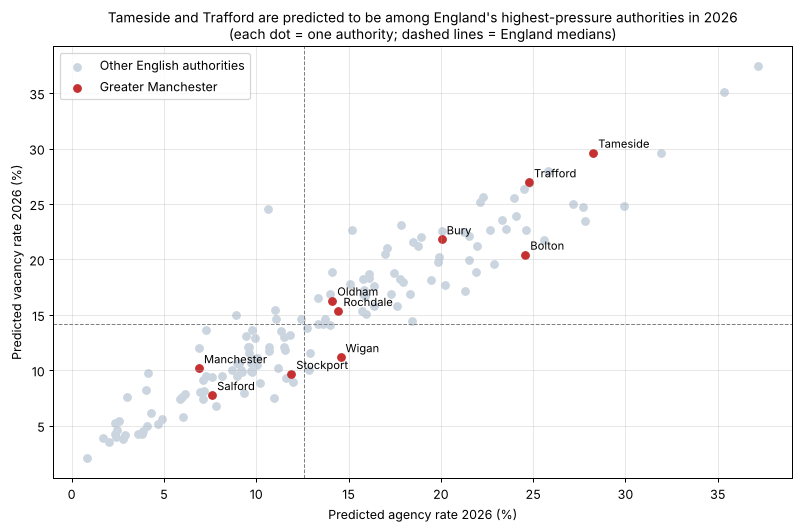

In [28]:
current = panel[panel.time_period == 2025].dropna(subset=m2_feats).copy()
for target, label in [("agency_rate_fte", "agency"), ("vacancy_rate_fte", "vacancy")]:
    p = make_panel(target)
    pipe = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50))).fit(p[m2_feats], p.y_next)
    current[f"pred_2026_{label}"] = pipe.predict(current[m2_feats])
    current[f"rank_{label}"] = current[f"pred_2026_{label}"].rank(ascending=False).astype(int)

gm_app = current[current.is_gm].set_index("la_name")[
    ["agency_rate_fte", "pred_2026_agency", "rank_agency",
     "vacancy_rate_fte", "pred_2026_vacancy", "rank_vacancy", "caseload_fte"]].sort_values("pred_2026_agency", ascending=False)
gm_app.columns = ["Agency 2025 (%)", "Predicted agency 2026 (%)", "England rank (agency)",
                  "Vacancy 2025 (%)", "Predicted vacancy 2026 (%)", "England rank (vacancy)", "Caseload 2025"]
print("Authorities scored in England:", len(current))
display(gm_app.round(1))

fig, ax = plt.subplots(figsize=(9, 6))
others, gm_pts = current[~current.is_gm], current[current.is_gm]
ax.scatter(others.pred_2026_agency, others.pred_2026_vacancy, color="#cbd5e0", label="Other English authorities")
ax.scatter(gm_pts.pred_2026_agency, gm_pts.pred_2026_vacancy, color=GM_COLOR, label="Greater Manchester")
for _, r in gm_pts.iterrows():
    ax.annotate(r.la_name, (r.pred_2026_agency, r.pred_2026_vacancy), xytext=(4, 4), textcoords="offset points", fontsize=9)
ax.axvline(current.pred_2026_agency.median(), ls="--", color="grey", lw=0.8)
ax.axhline(current.pred_2026_vacancy.median(), ls="--", color="grey", lw=0.8)
ax.set_xlabel("Predicted agency rate 2026 (%)"); ax.set_ylabel("Predicted vacancy rate 2026 (%)")
ax.set_title("Tameside and Trafford are predicted to be among England's highest-pressure authorities in 2026\n(each dot = one authority; dashed lines = England medians)", fontsize=11)
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

check_2024_2025 = gm[["agency_rate_fte", "vacancy_rate_fte"]].join(
    current[current.is_gm].set_index("la_name")[["agency_rate_fte", "vacancy_rate_fte"]], lsuffix=" 2024", rsuffix=" 2025")
print("Change in GM agency and vacancy rates, 2024 → 2025:")
display(check_2024_2025.round(1))

### Findings: Application to Greater Manchester

- **Tameside and Trafford** are predicted to have among the highest agency and vacancy rates in England in 2026: both rank within the top 11 of 146 scored authorities on each measure (Tameside 5th and 4th; Trafford 11th and 6th).
- **Bolton** ranks 14th for predicted agency rate and has the highest caseload in GM (20.8 cases per FTE in 2025). **Bury** is also above the England median on both measures.
- **Manchester, Salford and Stockport** are predicted to have low pressure, in the lower half nationally.
- **The national model confirms most of the GM profiles from Section 6.** The main exception is **Oldham**: its agency rate fell from 32% (2024) to 15% (2025) and its vacancy rate from 39% to 18%, so it is no longer predicted to be a high-pressure authority. Profiles should therefore be updated every year rather than treated as fixed.

### 10.1 Beyond Greater Manchester: Where Next?

**Why.** Bikal intends to generalise from GM to other markets. Because the model scores every English authority, the same scores identify where workforce pressure is likely to be highest in 2026. An authority is classed as **high pressure** if its predicted agency rate and predicted vacancy rate are both in the top quartile nationally.

In [29]:
q_agency, q_vacancy = current.pred_2026_agency.quantile(0.75), current.pred_2026_vacancy.quantile(0.75)
current["high_pressure"] = (current.pred_2026_agency >= q_agency) & (current.pred_2026_vacancy >= q_vacancy)
print(f"Top-quartile thresholds: agency ≥ {q_agency:.1f}%, vacancy ≥ {q_vacancy:.1f}%")
print("High-pressure authorities in England:", int(current.high_pressure.sum()), "of", len(current))
by_region = (current.groupby("region_name")
             .agg(authorities=("la_name", "size"), high_pressure=("high_pressure", "sum"),
                  mean_pred_agency=("pred_2026_agency", "mean"), mean_pred_vacancy=("pred_2026_vacancy", "mean"))
             .sort_values(["high_pressure", "mean_pred_agency"], ascending=False))
display(by_region.round(1))
top = current[current.high_pressure].sort_values("pred_2026_agency", ascending=False)
display(top[["la_name", "region_name", "pred_2026_agency", "pred_2026_vacancy", "caseload_fte"]].round(1).reset_index(drop=True))

Top-quartile thresholds: agency ≥ 18.7%, vacancy ≥ 19.9%
High-pressure authorities in England: 31 of 146
                          authorities  high_pressure  mean_pred_agency  mean_pred_vacancy
region_name                                                                              
North West                         24             10              17.1               17.0
Outer London                       18              6              18.4               20.3
Inner London                       11              5              16.8               18.2
South East                         19              5              14.2               15.0
South West                         14              4              14.3               15.3
East of England                    11              1              13.1               14.4
West Midlands                      14              0              11.2               13.0
North East                         11              0               9.7               

**Findings.** 31 of 146 authorities are high-pressure on both measures. They are concentrated in the **North West (10, including Tameside, Trafford, Bolton and Bury)** and **London (11)**, with smaller numbers in the South East and South West. None are in the North East, Yorkshire and the Humber, the East Midlands or the West Midlands. Outside GM, the North West high-pressure authorities include Cheshire East, Knowsley, Cumberland, Halton, Sefton and Liverpool.

**Business implication.** After GM, the natural next market is the rest of the North West: it holds the largest cluster of high-pressure authorities, is geographically adjacent, and could share infrastructure and reference sites with GM. Outer London (Havering, Harrow, Sutton, Ealing, Merton, Croydon) is the second cluster. Regions with no high-pressure authorities should be a lower priority for a workforce-focused proposition.

## 11. Implications for Bikal Technologies (O4)

Combining the descriptive profiles (Section 6) with the national model (Sections 8–10):

| Segment | Authorities | Evidence | DialogXR value proposition | Role in market entry |
|---|---|---|---|---|
| **Persistent workforce instability** | Tameside, Trafford (also Bury) | Among the highest agency and vacancy rates in GM; top 11 in England predicted for 2026 | Knowledge continuity: fast access to case history and summaries for new and agency staff | **Priority pilot sites** |
| **Workload pressure** | Bolton (also Stockport) | Highest caseload in GM; caseload predicts future agency and vacancy nationally | Reducing administrative and documentation time | Second-wave pilot; tests the workload link |
| **Stable, large scale** | Manchester, Salford | Low predicted pressure; Manchester has the largest budget | Efficiency at scale; consistent information across large teams | **Reference site** to demonstrate value |
| **Improving / monitor** | Oldham, Rochdale, Wigan | Near the England median in 2025; Oldham improved sharply | Re-assess with next year's data | Monitor |

**Key messages for Bikal**
1. **The market is credible.** GM spends more than £800m a year on CSC and has workforce pressure above the national level on every indicator.
2. **Lead with workload and stability, not cost savings.** The data do not show that workforce instability raises total spending (Model 1). They do show that workload predicts future workforce instability (Model 2).
3. **Target, do not broadcast.** Authorities differ sharply, so pilots should start where pressure is highest and most persistent.
4. **The approach generalises.** Model 2 scores every authority in England, so the same method can rank authorities in any new region without new data collection.

## 11.1 Feasibility: Costs, Time and Operational Barriers

**Why.** A recommendation is only useful if it can be implemented. This section combines the GM data with Bikal's own documentation (the DXR Rapid Review Functional Requirement Document, April 2025; the DialogXR Rapid Review development plan; and the Lenovo/Intel solution brief) to estimate the scale of use, the cost of a deployment and the break-even point.

**Assumptions** (all stated, all adjustable in the cell below)
- Development cost from Bikal's FRD: core development \$28,800 plus testing and QA \$5,000–7,000. Hardware is **not** costed by Bikal and is excluded.
- Exchange rate: £1 = \$1.27 (assumption; change as needed).
- Fully loaded cost of one social worker hour: £35, £45 and £55 (assumptions for a sensitivity range; no hourly cost is in the data).
- Rapid Review volume: Bikal's development plan reports an England average of 396 serious incident notifications a year. GM's share is estimated from its share of England's cases (an assumption: notifications are assumed proportional to caseload).

In [30]:
USD_PER_GBP = 1.27
dev_cost_usd = {"low": 28_800 + 5_000, "high": 28_800 + 7_000}
hourly_cost = [35, 45, 55]
ENGLAND_NOTIFICATIONS = 396

gm24 = csww[(csww.time_period == PROFILE_YEAR) & csww.is_gm]
eng24 = csww[csww.time_period == PROFILE_YEAR]
gm_case_share = gm24.cases.sum() / eng24.cases.sum()
scale_tbl = pd.Series({
    "GM social workers in post (FTE)": gm24.inpost_fte.sum(),
    "GM agency social workers (FTE)": gm24.agency_fte.sum(),
    "GM case-holding FTE": gm24.case_holders_fte.sum(),
    "GM cases": gm24.cases.sum(),
    "GM share of England cases (%)": 100 * gm_case_share,
    "Estimated GM serious incident notifications / year": ENGLAND_NOTIFICATIONS * gm_case_share,
})
display(scale_tbl.round(1).to_frame("Value"))

rows = []
for level, usd in dev_cost_usd.items():
    gbp = usd / USD_PER_GBP
    for hc in hourly_cost:
        hours = gbp / hc
        rows.append({"Development cost": level, "Cost (£)": gbp, "Hourly cost (£)": hc,
                     "Break-even hours (GM total)": hours,
                     "Hours per case-holding FTE": hours / gm24.case_holders_fte.sum(),
                     "Hours per serious-incident review": hours / (ENGLAND_NOTIFICATIONS * gm_case_share)})
breakeven = pd.DataFrame(rows)
display(breakeven.round(2))

# Pilot sizing: expected Rapid Reviews per GM authority (notifications assumed proportional to cases)
per_la = gm24.set_index("la_name")["cases"] / eng24.cases.sum() * ENGLAND_NOTIFICATIONS
pilot = pd.DataFrame({"Expected notifications / year": per_la.round(1),
                      "In a 6-month pilot": (per_la / 2).round(1)}).sort_values("Expected notifications / year", ascending=False)
display(pilot)
print(f"Tameside + Manchester, 6 months: {(per_la[['Tameside', 'Manchester']].sum() / 2):.1f} reviews")
print(f"All GM, 12 months: {per_la.sum():.1f} reviews")

                                                      Value
GM social workers in post (FTE)                      2128.4
GM agency social workers (FTE)                        562.0
GM case-holding FTE                                  1311.9
GM cases                                            21490.0
GM share of England cases (%)                           6.8
Estimated GM serious incident notifications / year     27.1
  Development cost  Cost (£)  Hourly cost (£)  Break-even hours (GM total)  Hours per case-holding FTE  Hours per serious-incident review
0              low  26614.17               35                       760.40                        0.58                              28.11
1              low  26614.17               45                       591.43                        0.45                              21.86
2              low  26614.17               55                       483.89                        0.37                              17.89
3             high  28188.98

### Findings: Feasibility

**Cost and break-even.** On Bikal's own development estimate (£26,600–28,200 at the assumed exchange rate), a GM-wide deployment breaks even if it saves roughly **480–810 social worker hours in total** across the region in its first year, which is under one hour (0.4–0.6 hours) per case-holding social worker. Expressed per serious-incident review (about 27 a year in GM, on the stated assumption), break-even requires saving roughly 18–30 hours per review. This is plausible given that each Rapid Review draws on 6–12 agency reports of 6–12 pages each and must be completed in 15 working days, but it is **not yet evidenced**: the "up to 90% reduction in case-review research time" in Bikal's solution brief is a vendor claim, not an independent result. These figures exclude hardware, information governance, training and integration costs, which are likely to be larger than development cost, so they are a lower bound.

**Time.** Bikal's FRD estimates 20–24 weeks of development effort (7–10 weeks elapsed delivery), and its development plan sets out a 14-week phased build (planning 1 week; data collection and pre-processing 3; infrastructure 1; model development 4; UI/UX 4; final adjustments 1). Public-sector procurement and governance approvals would add to this.

**Operational barriers**

| Barrier | Evidence | Mitigation |
|---|---|---|
| Integration with case management systems | The FRD lists integration with existing systems as an open, unscoped area | Start with the Rapid Review workflow, which works on uploaded documents and does not need live integration |
| Information governance and multi-agency data sharing | Rapid Reviews draw on police, health, education and probation records | Data Protection Impact Assessment and data-sharing agreements with the safeguarding partnership before any pilot |
| On-premises hardware | DialogXR is designed for air-gapped, on-premises servers (Lenovo ThinkSystem); GPU recommended for 2–3 hour audio transcription | Use the validated CPU-only profile for text workflows; add GPU only if audio volumes justify it |
| Training data | The development plan requires good-practice Rapid Reviews, supporting documents and meeting transcripts from partnerships | Agree a data-supply arrangement with one partnership and, ideally, the National Panel |
| Adoption capacity | The authorities with the highest need (Tameside, Trafford) have the least stable workforces to absorb a new tool | Pair the pilot with a reference site with a stable workforce (Manchester or Salford); keep training short and role-based |
| Accuracy and accountability | LLM outputs can be wrong; safeguarding decisions are high stakes | Human sign-off on every output; evidence-linked citations; audit trail (all described in Bikal's design) |

## 12. Evaluation Framework for a DialogXR Pilot (O4)

The indicators above describe the **context** in which DialogXR would operate. They are influenced by many external factors, so changes in them would not prove that DialogXR worked. A pilot therefore needs two layers:

- **Layer 1: System context.** The indicators from this notebook, updated every year to track the operating environment.
- **Layer 2: DialogXR-sensitive outcomes.** Direct measures of the activities DialogXR supports, collected before and after implementation.

For each Layer 2 outcome *j*: $\Delta_j = \text{Post}_j - \text{Pre}_j$. Outcomes are reported separately rather than combined into one score. For time-based outcomes, a reduction is an improvement; for usefulness and completeness, an increase is an improvement.

In [31]:
evaluation_framework = pd.DataFrame({
    "Layer": ["1. System context"] * 5 + ["2. DialogXR outcome"] * 6,
    "Measure": ["Caseload per FTE", "Agency rate", "Vacancy rate", "Turnover rate", "Spend per case",
                "Time to retrieve case information", "Case review preparation time",
                "Time to produce case summaries / chronologies", "Documentation and report-writing time",
                "Onboarding time for new and agency staff", "User adoption and perceived usefulness"],
    "Link to this analysis": ["Predicts future agency and vacancy (Section 9)", "Model 2 outcome", "Model 2 outcome",
                              "Monitor only (not predictable)", "Financial context (Model 1)",
                              "Knowledge continuity", "Workload", "Knowledge continuity", "Workload",
                              "Workforce instability segment", "Adoption"],
    "Baseline available now": ["Yes"] * 5 + ["No"] * 6,
    "In pilot": ["Monitor yearly"] * 5 + ["Measure pre / post"] * 6,
})
display(evaluation_framework)

                  Layer                                        Measure                           Link to this analysis Baseline available now            In pilot
0     1. System context                               Caseload per FTE  Predicts future agency and vacancy (Section 9)                    Yes      Monitor yearly
1     1. System context                                    Agency rate                                 Model 2 outcome                    Yes      Monitor yearly
2     1. System context                                   Vacancy rate                                 Model 2 outcome                    Yes      Monitor yearly
3     1. System context                                  Turnover rate                  Monitor only (not predictable)                    Yes      Monitor yearly
4     1. System context                                 Spend per case                     Financial context (Model 1)                    Yes      Monitor yearly
5   2. DialogXR outcome     

## 13. Summary and Limitations

### From Analysis to Business Implication

| Analysis | Why this method | Result | Business implication |
|---|---|---|---|
| Market scale (RO3) | Size of the addressable budget | GM CSC ≈ £826m; CLA ≈ 55% | Credible market size (O1) |
| Pooled GM vs England, 2024 | Fair regional comparison, weighted by workforce | GM above England on all four indicators | Need is real (O2) |
| Trend 2017–2025 | Persistence of the problem | Caseload above England every year; vacancy above since 2022, agency since 2023 | Workload is the long-standing problem (O2) |
| Correlations and profiles (GM) | Structure of the problem; segmentation | Workforce instability cluster vs workload pressure | Different value propositions per segment (O3) |
| Model 1: OLS, log spend | Test the cost-saving argument | No robust link between workforce pressure and spending | Do not lead with cost savings |
| Model 2: OLS / Ridge / Lasso | Predict next year's pressure | R² ≈ 0.70 (agency), 0.63 (vacancy), beating persistence | Early-warning tool for any region (O3, O4) |
| Inference with fixed effects | Explain what matters, with valid uncertainty | Caseload significantly predicts future agency and vacancy | Position DialogXR on workload; test this in a pilot |
| GM application | Apply the model to the case study | Tameside, Trafford highest; Manchester, Salford lowest | Pilot and reference-site selection (O4) |

### Limitations

1. **Observational data.** All results are associations and predictions, not causal effects. In particular, the models do not show that DialogXR would change any indicator.
2. **Unobserved causes.** The data do not capture demand (e.g. referrals, deprivation), placement availability or local labour markets, which may drive both workload and workforce pressure.
3. **One year of financial data.** RO3 covers 2023–24 only, so Model 1 is cross-sectional.
4. **Small GM sample.** The GM correlations and profiles (n = 10) are descriptive; the national models (n ≈ 140–1,150) provide the statistical evidence.
5. **No administrative-time data.** CSWW does not measure how much time social workers spend on administration, so the mechanism linking workload to DialogXR must be measured in a pilot (Section 12).
6. **2025 shock.** All indicators improved nationally in 2025. Year fixed effects absorb this in the inference model; the predictive model does not model it explicitly.

## 14. Verification: Standard Errors Recomputed with statsmodels

**Why.** HC3 and cluster-robust standard errors in Sections 7 and 9 were written by hand in NumPy, because statsmodels could not be installed in the environment where the analysis was built. This cell recomputes them with statsmodels, a standard and widely tested library. If the two columns match, the hand-written code is correct. Run it anywhere statsmodels is installed (for example, Google Colab or Anaconda).

In [32]:
try:
    import statsmodels.api as sm
except ImportError:
    sm = None
    print("statsmodels is not installed here. Run `pip install statsmodels` and rerun this cell.")

if sm is not None:
    # Model 1: HC3 robust standard errors
    d = model1_data(2024)
    fit = sm.OLS(d["log_spend"].values, sm.add_constant(d[m1_vars].values)).fit(cov_type="HC3")
    own = ols_hc3(d["log_spend"].values, d[m1_vars].values, m1_vars)[0]
    check1 = pd.DataFrame({"coef (own)": own["coef"].values, "coef (statsmodels)": fit.params,
                           "SE (own)": own["se (HC3)"].values, "SE (statsmodels)": fit.bse},
                          index=["const"] + m1_vars)
    print("Model 1, HC3 standard errors")
    display(check1.round(4))

    # Inference model: cluster-robust standard errors by authority
    for target in ["agency_rate_fte", "vacancy_rate_fte"]:
        p = make_panel(target)
        year_fe = pd.get_dummies(p.time_period, prefix="year", drop_first=True).astype(float)
        X = np.column_stack([p[m2_feats].values, year_fe.values])
        groups = pd.factorize(p.new_la_code)[0]
        fit = sm.OLS(p.y_next.values, sm.add_constant(X)).fit(cov_type="cluster", cov_kwds={"groups": groups})
        own = ols_clustered(p.y_next.values, X, p.new_la_code.values, m2_feats + list(year_fe.columns))[0]
        k = len(m2_feats) + 1
        check2 = pd.DataFrame({"coef (own)": own["coef"].values[:k], "coef (statsmodels)": fit.params[:k],
                               "SE (own)": own["se (clustered)"].values[:k], "SE (statsmodels)": fit.bse[:k]},
                              index=["const"] + m2_feats)
        print(f"\nInference model, next-year {wf_labels[target]}, clustered standard errors")
        display(check2.round(4))
        print("Maximum SE difference:", float(np.abs(check2["SE (own)"] - check2["SE (statsmodels)"]).max()))

statsmodels is not installed here. Run `pip install statsmodels` and rerun this cell.
